# Frequent itemsets (Role E · Mine co-occurring side effects)
Every review becomes a **basket**: the set of side effects the patient says they had. On these baskets we run **A-priori** and **PCY**, both written from scratch, to find the side effects that are reported together, turn them into **association rules** with a significance test, and compare the rules between the drugs of one condition. This answers research question 2 of the project plan: *which side effects co-occur, and do the combinations differ between drugs for the same condition?*

| Step | What | Output |
|---|---|---|
| E1 | Load the clean reviews of Role A, one family name per drug, scope (4 conditions) | |
| E2 | The side-effect lexicon: 57 concepts, 450 patient phrasings, built in three versions | |
| E3 | The extractor: regex match, negation, hypothetical and treated-condition filters | |
| E4 | Baskets of all reviews in scope, descriptive statistics | **`baskets.parquet`**, `drug_side_effect_profiles.csv` (for D), `condition_concept_heatmap.png`, `rating_by_n_side_effects.png` |
| E5 | Support threshold: sensitivity analysis | `support_sensitivity.png` |
| E6 | A-priori from scratch, checked against brute-force counting | `frequent_itemsets.csv` |
| E7 | PCY from scratch, checked against A-priori | |
| E8 | Benchmark A-priori vs PCY on the baskets of the four conditions | `benchmark.csv`, `benchmark_real.png` |
| E9 | Association rules with lift, Fisher's exact test and Benjamini-Hochberg | `rules_by_condition.csv`, `cooccurrence_networks.png` |
| E10 | Do the combinations differ between drugs? Universal vs drug-specific pairs | `rules_by_drug.csv`, `pair_classification.csv`, `drug_lift_heatmap_birth_control.png`, `drug_specific_pairs.png` |

All numbers for the report are collected in `run_stats` and saved to `role_e_run_stats.json` at the end.

Methods: Leskovec, Rajaraman & Ullman, *Mining of Massive Datasets*, ch. 6 (A-priori, PCY, association rules); Park, Chen & Yu (1995) for PCY; Chapman et al. (2001), *NegEx*, for the negation rule.

## Which lexicon, and why
The project plan left open how to recognise side effects in free text. Three options were considered:

| Option | What it is | Why not / why yes |
|---|---|---|
| **MedDRA / SIDER terms** | The medical vocabularies used for adverse-event reports (*nausea*, *insomnia*, *alopecia*) | Patients do not write like that: they write *"couldn't sleep"*, *"my hair is falling out"*, *"gained 20 lbs"*. A direct match of medical terms finds a small share of the mentions. SIDER is also organised by drug, not by phrasing |
| **A classifier** | Train a model to tag side effects in sentences | Needs thousands of labelled sentences, which we do not have, and its output is hard to inspect |
| **Our own lexicon of lay phrasings** ✔ | 57 side-effect concepts, each with the ways patients write it, matched with regular expressions and context rules | Every match can be read and checked; mistakes are fixed by editing a JSON file; it was built *from the reviews* (E2), so it covers how these patients write |

The price of a hand-built lexicon is **recall**: effects phrased in a way we did not list are missed. We measured it on a blind sample (E2) and accept it, because the itemset analysis needs clean, frequent concepts more than it needs every rare phrasing.

## 0 · Setup and parameters
All settings live here. To experiment, change a value and run the notebook again.

In [1]:
import json
import math
import re
import time
import tracemalloc
from collections import Counter
from itertools import chain, combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import fisher_exact

pd.set_option('display.max_colwidth', 160)
pd.set_option('display.max_rows', 120)
pd.set_option('display.width', 200)
NOTEBOOK_STARTED = time.perf_counter()

# where the data is read from and written to
INPUT_DIRS = [Path('/kaggle/input'), Path('data'), Path('../data-cleaning-and-lsh/outputs')]   # Role A's output (Kaggle), a local copy, or A's local run
LEXICON_DIRS = [Path('.'), Path('lexicon'), Path('/kaggle/input')]  # this folder, or the lexicon uploaded as a Kaggle dataset
OUTPUT_DIR = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('outputs')
FIGURE_DIR = OUTPUT_DIR / 'figures'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# E1 scope
CONDITIONS = ['Birth Control', 'Depression', 'Pain', 'Acne']   # the four conditions of the project plan
NEGATIVE_RATING_MAX = 4           # a review with rating <= 4 is "negative"

# E2 lexicon files (v3 is the one used; v1 and v2 only for the comparison of versions)
LEXICON_FILES = {'v1': 'side_effect_lexicon_v1.json', 'v2': 'side_effect_lexicon_v2.json', 'v3': 'side_effect_lexicon.json'}
EXPANSION_FILE = 'lexicon_expansion_candidates_filled.xlsx'   # the 300 phrases reviewed to build v2
# Measured on the blind validation of the extractor (round 2: 80 reviews not used to build the lexicon;
# gold labels annotated by an LLM (Claude) that saw only the review text, never the extractor's output).
# The full evaluation (two rounds, per-concept scores, ablation) is in the archived validation notebook.
EXTRACTOR_PRECISION, EXTRACTOR_RECALL = 0.74, 0.67

# E3 extractor
NEGATION_WINDOW = 5               # tokens before a match in which a negation counts (NegEx uses 5)
HYPOTHETICAL_WINDOW = 6           # tokens before a match in which "worried about", "heard" counts

# E5-E7 frequent itemsets
MIN_SUPPORT = 0.005               # itemset frequent if reported by >= 0.5 % of the condition's reviews ...
MIN_COUNT_FLOOR = 20              # ... and by at least 20 reviews
SUPPORTS_TO_COMPARE = [0.0025, 0.005, 0.01, 0.02, 0.05]   # thresholds of the sensitivity analysis (E5)
MAX_ITEMSET_SIZE = 3              # items, pairs and triples
N_BUCKETS = 10_000                # PCY buckets on the real data
RANDOM_SEED = 42

# E8 benchmark
BENCHMARK_REPEATS = 5             # time = median of this many runs
BUCKET_SIZES_REAL = [10 ** 2, 10 ** 3, 10 ** 4, 10 ** 5]   # numbers of PCY buckets compared on Birth Control

# E9-E10 association rules
MIN_RULE_COUNT = 20               # a rule needs at least this many reviews with X and Y
MIN_CONFIDENCE = 0.1
MIN_LIFT = 1.0
FDR = 0.05                        # false discovery rate of Benjamini-Hochberg
MIN_REVIEWS_PER_DRUG = 200        # drugs compared in E10 need this many reviews in the condition
NETWORK_MIN_LIFT = 1.5            # edges of the co-occurrence networks

# figure style: one colour per condition (fixed order, colour-blind safe), one sequential blue ramp
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.lines import Line2D
CONDITION_COLOURS = {'Birth Control': '#2a78d6', 'Depression': '#eb6834', 'Pain': '#1baf7a', 'Acne': '#eda100'}
ALGORITHM_COLOURS = {'apriori': '#2a78d6', 'pcy': '#eb6834'}
ALGORITHM_NAMES = {'apriori': 'A-priori', 'pcy': 'PCY'}
BLUES = LinearSegmentedColormap.from_list('blues', ['#f4f8fe', '#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])
LIFT_COLOURS = LinearSegmentedColormap.from_list('lift', ['#1c5cab', '#86b6ef', '#f0efec', '#f19a99', '#b8302f'])
INK, MUTED, GRID = '#2b2b29', '#6b6a63', '#e8e7e1'


def clean_axes(ax):
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    for side in ('left', 'bottom'):
        ax.spines[side].set_color('#c9c8c0')
    ax.tick_params(colors=MUTED, labelcolor=INK)
    ax.grid(axis='y', color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)


def plain_log_x(ax, ticks, labels):
    # log x axis with only our own tick labels (no '3x10^3' minor labels)
    from matplotlib.ticker import NullFormatter, NullLocator
    ax.set_xscale('log')
    ax.xaxis.set_minor_locator(NullLocator())
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_xticks(ticks, labels)


def save_figure(fig, name):
    fig.savefig(FIGURE_DIR / name, dpi=200, bbox_inches='tight')


run_stats = {}              # every number for the report is collected here
print('outputs go to', OUTPUT_DIR)

outputs go to outputs


## E1 · Load the clean reviews and set the scope
The input is Role A's output: `reviews_clean_deduplicated.parquet` (128,663 reviews, no copies) and `drug_families.csv` (brand and generic names of the same medicine). On Kaggle both come from *Add Input → Notebook Output → "Clean and deduplicate"*; locally they are read from `data/`.

**One name per medicine.** A review keeps either the brand (*Nexplanon*) or the generic name (*Etonogestrel*). To compare drugs every name gets its **family name** (the most reviewed name of the family `drug_families.csv`), so both reviews count for the same medicine.

**Scope: four conditions.** The lexicon and its context rules are built for the four conditions of the project plan, which together are a quarter of the dataset and cover very different medicines (hormonal contraceptives, antidepressants, painkillers, acne drugs). Those are: 
- Birth control. 
- Depression. 
- Pain.
- Acne. 

We use the column `review_text_clean`, which keeps punctuation and apostrophes, important for negations. 

In [2]:
def find_input(file_name):
    # Role A's output: on Kaggle under /kaggle/input, locally in data/
    for folder in INPUT_DIRS:
        if folder.exists():
            matches = sorted(folder.rglob(file_name))
            if matches:
                return matches[0]
    raise FileNotFoundError(f'{file_name} not found. On Kaggle: Add Input -> Notebook Output -> "Clean and deduplicate"; '
                            f'locally: copy it to data/')


def find_lexicon_file(file_name):
    for folder in LEXICON_DIRS:
        if folder.exists():
            matches = sorted(folder.rglob(file_name))
            if matches:
                return matches[0]
    raise FileNotFoundError(f'{file_name} not found next to the notebook or in lexicon/')


reviews = pd.read_parquet(find_input('reviews_clean_deduplicated.parquet'))
drug_families = pd.read_csv(find_input('drug_families.csv'))
assert len(reviews) == 128_663, f'expected the 128,663 clean reviews of Role A, got {len(reviews):,}'

# one family name per drug name
family_of_drug_name = {name: family.drug_family_name
                       for family in drug_families.itertuples() for name in family.drug_names.split(' | ')}
reviews['drug_family'] = reviews['drug_name'].map(family_of_drug_name)
assert reviews['drug_family'].notna().all(), 'every drug name should belong to a family'

# selected reviews that treat the mentioned conditions
scoped_reviews = reviews[reviews['condition_name'].isin(CONDITIONS)].reset_index(drop=True)
scope_table = scoped_reviews.groupby('condition_name').agg(
    n_reviews=('review_id', 'size'), n_drugs=('drug_family', 'nunique'), mean_rating=('rating', 'mean'),
    share_negative=('rating', lambda r: (r <= NEGATIVE_RATING_MAX).mean())).reindex(CONDITIONS).round(3)

run_stats['n_reviews_all'] = int(len(reviews))
run_stats['n_reviews_in_scope'] = int(len(scoped_reviews))
run_stats['n_drug_families_in_scope'] = int(scoped_reviews['drug_family'].nunique())
run_stats['scope_by_condition'] = scope_table.to_dict(orient='index')
print(f'{len(scoped_reviews):,} of {len(reviews):,} reviews are in scope ({len(scoped_reviews) / len(reviews):.0%}), '
      f'{scoped_reviews["drug_family"].nunique()} drug families')
scope_table

36,365 of 128,663 reviews are in scope (28%), 168 drug families


,n_reviews,n_drugs,mean_rating,share_negative
condition_name,,,,
Birth Control,19520,19,6.083,0.351
Depression,7109,52,7.132,0.218
Pain,5187,72,7.585,0.176
Acne,4549,34,7.362,0.200


The four conditions give 36,365 reviews (28 % of the dataset). Birth Control alone has more than half of them, Acne the fewest. 

## E2 · The side-effect lexicon
`side_effect_lexicon.json` lists 57 **concepts** (the items of the baskets: `weight_gain`, `nausea`, `no_period`, ...), grouped in 9 families, and for each concept the **variants**: the ways patients write it. Every variant registered in the review is matched with a concept.  


**Concepts whose negation is part of the pattern.** For some effects the patient's words *are* a negation: *"no period"*, *"haven't stopped bleeding"*, *"couldn't sleep"*, *"no appetite"*, *"no sex drive"*. These are flagged `negation_in_pattern` in the lexicon so that E3 does not drop them as negated. A few concepts carry extra context rules (shown in the table below): `only_conditions` (*acne_worsening* only makes sense in Acne; elsewhere it counts as *acne_breakout*), `not_preceded_by` (*"passing blood clots"* is menstrual, not thrombosis) and `requires_in_clause` (*"ten times worse"* only counts as acne worsening if the clause mentions acne or skin).

**How it was built, in three versions.**
1. **v1** (49 concepts, 298 variants): written by hand from the project plan and a first read of reviews.
2. **v2** (57 concepts, 383 variants): We counted the 300 most frequent 2- and 3-word phrases of **negative reviews with an empty basket** and reviewed them one by one in `lexicon/lexicon_expansion_candidates_filled.xlsx`; the 32 phrases that were side effects gave 8 new concepts (*spotting*, *no_period*, *acne_worsening*, ...) and new variants of 5 existing ones.
3. **v3** (57 concepts, 450 variants): Fixes from the error review of a blind validation sample of 200 reviews (`lexicon/validation_sample_annotated.xlsx`: for each review, the side effects the patient really reported in the column `gold_basket`, plus notes on the doubtful cases). Patients deny their period with a verb (*"I didn't get a period"*), describe prolonged bleeding with durations (*"6 week long period"*; durations must be long, 5 days is a normal period), and use *depressed* for reactions to something else (*"depressed about my weight"*, now blocked with `!about`). 


**Results of the lexicon:**  On a blind validation sample of 80 unseene reviews the extractor reaches **precision 0.74 and recall 0.67** (weighted to the real mix of reviews). Three out of four extracted side effects are right, and two out of three reported side effects are found; the misses are mostly phrasings not in the lexicon.

In [3]:
def load_lexicon(path):
    # the list of concept dicts stored in the JSON file
    with open(path, encoding='utf-8') as f:
        return json.load(f)['concepts']


lexicons = {version: load_lexicon(find_lexicon_file(file_name)) for version, file_name in LEXICON_FILES.items()}
lexicon = lexicons['v3']                                   # the one used from here on
CONCEPTS = [c['concept'] for c in lexicon]
CONCEPT_ID = {concept: i for i, concept in enumerate(CONCEPTS)}   # A-priori and PCY work on integer ids

lexicon_versions = pd.DataFrame([{'version': v, 'n_concepts': len(L), 'n_variants': sum(len(c['variants']) for c in L)}
                                 for v, L in lexicons.items()]).set_index('version')
run_stats['lexicon_versions'] = lexicon_versions.to_dict(orient='index')
run_stats['n_concepts'] = len(CONCEPTS)
run_stats['n_variants'] = int(lexicon_versions.loc['v3', 'n_variants'])
run_stats['extractor_validation'] = {'precision': EXTRACTOR_PRECISION, 'recall': EXTRACTOR_RECALL, 'n_reviews': 80,
                                     'round': 2, 'gold_labels': 'LLM-annotated (Claude), blind to the extractor'}
display(lexicon_versions)

RULE_KEYS = ['negation_in_pattern', 'only_conditions', 'elsewhere_counts_as', 'not_preceded_by', 'requires_in_clause', 'not_followed_by']
lexicon_table = pd.DataFrame([{
    'group': c['group'], 'concept': c['concept'], 'n_variants': len(c['variants']),
    'examples': ' · '.join(c['variants'][:3]),
    'context rules': ', '.join(f"{k}={c[k]}" if not isinstance(c[k], bool) else k for k in RULE_KEYS if c.get(k)),
} for c in lexicon]).sort_values(['group', 'concept'], ignore_index=True)
print(f'{len(CONCEPTS)} concepts in {lexicon_table["group"].nunique()} groups')
lexicon_table

,n_concepts,n_variants
version,,
v1,49,298
v2,57,383
v3,57,450


57 concepts in 9 groups


,group,concept,n_variants,examples,context rules
0,cardiovascular,blood_clots,9,blood clot · clot in my lung · clots in my lungs,"not_preceded_by=['passing', 'passed', 'pass']"
1,cardiovascular,chest_pain,4,chest pain · chest tightness · tight chest,
2,cardiovascular,high_blood_pressure,8,high blood pressure · blood pressure went up · blood pressure rose,
3,cardiovascular,palpitations,6,palpitation · racing heart · heart racing,
4,cardiovascular,shortness_of_breath,7,shortness of breath · short of breath · trouble breathing,negation_in_pattern
5,digestive,bloating,4,bloating · bloated · gassy,
6,digestive,constipation,2,constipation · constipated,
7,digestive,diarrhea,5,diarrhea · diarrhoea · diarrhia,
8,digestive,nausea,6,nausea · nauseous · nauseated,
9,digestive,stomach_pain,9,stomach pain · stomach ache · stomachache,


### Compile the lexicon into one regular expression

In [5]:
NUMBER_WORDS = ('one|two|three|four|five|six|seven|eight|nine|ten|eleven|twelve|fifteen|twenty|'
                'thirty|forty|fifty|a few|a couple of|a couple|several|many')
QUALIFIER = r"(?:(?:about|almost|over|nearly|around|like|at least|up to|probably)\s+)?"
NUMBER = rf"{QUALIFIER}(?:\d+(?:\.\d+)?|{NUMBER_WORDS})"
MANY = (rf"{QUALIFIER}(?:1\.\d+|[2-9](?:\.\d+)?|[1-9]\d+|two|three|four|five|six|seven|eight|nine|ten|eleven|twelve|"
        r"fifteen|twenty|thirty|a few|a couple of|a couple|several|many)")
NDAYS = rf"{QUALIFIER}(?:[1-9]\d+|ten|eleven|twelve|fifteen|twenty|thirty|forty|fifty)"
UNIT = r"(?:lbs?|pounds?|kgs?|kilos?|kilograms?)"
GAP = r"(?:(?!(?:no|not|never|nothing)\b)[a-z0-9']+[\s-]+){0,3}"   # up to 3 words that are not negations
PLURAL = r"(?:s|es)?"
SPACE = r"[\s-]+"          # "light headed" also matches "light-headed"
PLACEHOLDERS = {'<n>': NUMBER, '<many>': MANY, '<ndays>': NDAYS, '<unit>': UNIT, '<...>': GAP}


def variant_to_regex(variant, not_followed_by=()):
    # 'gained <n> <unit>' -> a regex string
    tokens = variant.lower().split()
    not_followed_by = list(not_followed_by) + [t[1:] for t in tokens if t.startswith('!')]   # trailing "!word" tokens
    tokens = [t for t in tokens if not t.startswith('!')]
    regex = ''
    for i, token in enumerate(tokens):
        if i > 0 and tokens[i - 1] != '<...>':      # the gap already ends with a space
            regex += r'\s*' if token == '<unit>' else SPACE
        regex += PLACEHOLDERS.get(token) or re.escape(token)
    if tokens[-1] not in PLACEHOLDERS:
        regex += PLURAL
    regex = r'\b' + regex + r'\b'
    if not_followed_by:
        regex += '(?!' + '|'.join(r'\s+' + re.escape(w) + r'\b' for w in not_followed_by) + ')'
    return regex


class CompiledLexicon:
    """One big regex (longest variant first) plus the context rules of the concepts."""

    def __init__(self, concept_list):
        variants = [(variant, c['concept'], variant_to_regex(variant, c.get('not_followed_by', ())))
                    for c in concept_list for variant in c['variants']]
        variants.sort(key=lambda v: len(v[0]), reverse=True)       # longest first
        # Speed: group the alternatives by first letter, so at each position the regex engine only
        # tries the variants that can start there. Variants starting with a placeholder have no shortcut.
        by_first_letter, self.concept_of_group = {}, {}
        for i, (variant, concept, regex) in enumerate(variants):
            key = '' if variant.startswith('<') else variant[0]
            by_first_letter.setdefault(key, []).append(f'(?P<v{i}>{regex})')
            self.concept_of_group[f'v{i}'] = concept
        self.pattern = re.compile(r'\b(?:' + '|'.join(
            (f'(?={re.escape(letter)})' if letter else '') + '(?:' + '|'.join(alternatives) + ')'
            for letter, alternatives in sorted(by_first_letter.items())) + ')')
        self.concepts = [c['concept'] for c in concept_list]
        self.negation_in_pattern = {c['concept'] for c in concept_list if c.get('negation_in_pattern')}
        self.only_conditions = {c['concept']: set(c['only_conditions']) for c in concept_list if 'only_conditions' in c}
        self.elsewhere_counts_as = {c['concept']: c['elsewhere_counts_as'] for c in concept_list if 'elsewhere_counts_as' in c}
        self.not_preceded_by = {c['concept']: set(c['not_preceded_by']) for c in concept_list if 'not_preceded_by' in c}
        self.requires_in_clause = {c['concept']: re.compile(r'\b(?:' + '|'.join(map(re.escape, c['requires_in_clause'])) + r')')
                                   for c in concept_list if 'requires_in_clause' in c}


LEXICON = CompiledLexicon(lexicon)
print(f'{len(LEXICON.concept_of_group)} variants compiled into one regex of {len(LEXICON.pattern.pattern):,} characters')
print('example:', 'gained <n> <unit>', '->', variant_to_regex('gained <n> <unit>'))

450 variants compiled into one regex of 26,697 characters
example: gained <n> <unit> -> \bgained[\s-]+(?:(?:about|almost|over|nearly|around|like|at least|up to|probably)\s+)?(?:\d+(?:\.\d+)?|one|two|three|four|five|six|seven|eight|nine|ten|eleven|twelve|fifteen|twenty|thirty|forty|fifty|a few|a couple of|a couple|several|many)\s*(?:lbs?|pounds?|kgs?|kilos?|kilograms?)\b


## E3 · The extractor: from a review to its basket
For one review, find every lexicon match and decide whether it counts as a side effect the patient **had**. The basket is the set of concepts with at least one kept mention.

The text is lowercased, apostrophes are unified (*"dont"* → *"don't"*) and it is split into **clauses** at `. ! ? ;`, line breaks and the adversative words *but / however / although / though / except*. A clause is the scope of a negation: in *"I didn't get nausea, but it gave me headaches"* the *didn't* only reaches *nausea*. Then every match is flagged:

| Flag | Rule | Example (dropped) |
|---|---|---|
| **negated** | a negation word (*no, not, never, without, didn't, free of, ...*) in the `NEGATION_WINDOW` = 5 tokens before the match, inside the clause, or a post-negation right after it (*"... was not an issue"*, *"... none"*). Pseudo-negations (*"not only"*, *"no doubt"*, *"never felt so"*) are removed first | *"no nausea"*, *"headaches were not a problem"* |
| **hypothetical** | a fear / hearsay trigger in the 6 tokens before (*worried, afraid, heard, read, may cause, risk of, ...*) | *"I was worried about weight gain"* |
| **excluded_indication** | the concept is the condition being treated: acne in Acne, depressed mood in Depression, muscle/joint pain in Pain. Anxiety in Depression is also excluded (patients name it as a co-treated condition), **unless** a causal cue close to the mention says the drug caused it (*"it gave me panic attacks"*) and the clause has no cue of indication (*"helped with my anxiety"*) | *"it cured my acne"*, *"for my depression and anxiety"* |

Decisions, documented for the report: a side effect that **went away** still counts (the patient had it); *"no more X"* / *"no longer X"* is negated (it describes a benefit); one affirmative mention is enough even if the same concept is negated elsewhere in the review; `acne_worsening` (*"my acne got worse"*) is a side effect in Acne, where acne itself is the indication.

**Known limits.** A negation reaches everything in its 5-token window: in *"constipation was not an issue, just some dizziness"* the *not* also drops *dizziness*. Side effects phrased in a way the lexicon does not list are missed (recall 0.67, E2).

In [7]:
INDICATION_EXCLUSIONS = {
    'Acne': {'acne_breakout'},
    'Depression': {'depressed_mood', 'anxiety'},   # anxiety: usually a co-treated condition ("for my depression and anxiety")
    'Pain': {'muscle_joint_pain'},
    'Birth Control': set(),
}
# An excluded concept still counts if the words around it say the drug caused it. The causal cue must be
# close (8 tokens before, 6 after, same clause) and a cue of indication in the clause cancels it.
OVERRIDE_BEFORE, OVERRIDE_AFTER = 8, 6
INDICATION_OVERRIDES = {
    ('Depression', 'anxiety'): re.compile(
        r"\b(?:gave me|giving me|given me|caused|causing|made me|made my|makes me|"
        r"triggered|brought on|started having|started getting|began having|began to have|"
        r"became|more anxious|more anxiety|went up|increased|worse|worsened|side effects?)\b"),
}
INDICATION_CUES = re.compile(
    r"\b(?:help(?:ed|s|ing)? (?:with|my)|good for|great for|works? for|worked for|"
    r"for (?:my )?(?:depression|anxiety)\w*|treat(?:s|ed|ing|ment)?|diagnosed|struggl\w* with|"
    r"suffer\w* (?:from|with)|history of|prescribed|decreas\w*|reduc\w*|less anxi\w*)\b")

CLAUSE_BOUNDARY = re.compile(r"[.!?;\n]+|\b(?:but|however|although|though|except|aside from|apart from)\b")
TOKEN = re.compile(r"[a-z0-9']+")
PRE_NEGATION = re.compile(
    r"\b(?:no|not|never|without|none|zero|nor|"
    r"didn't|don't|doesn't|haven't|hasn't|hadn't|wasn't|weren't|isn't|aren't|won't|"
    r"free of|lack of|absence of|no sign of)\b")
PSEUDO_NEGATION = re.compile(
    r"\b(?:not only|not just|no doubt|not sure if|no wonder|never been so|never had such|never had so|never felt so)\b")
POST_NEGATION = re.compile(
    r"^\W*(?:(?:was|were|is|are|has been|have been)\s+)?(?:not|never)\s+(?:an?\s+|any\s+)?(?:issue|problem|concern)\b"
    r"|^\W*(?:wasn't|weren't|isn't|aren't|hasn't been|haven't been)\s+(?:an?\s+|any\s+)?(?:issue|problem|concern)\b"
    r"|^\W*(?:is|was|are|were)\s+gone\b"
    r"|^\W*:?\s*none\b")
HYPOTHETICAL = re.compile(
    r"\b(?:worried|worry|afraid|scared|feared|fear of|heard|read|reviews|warned|"
    r"may cause|might cause|can cause|could cause|risk of|in case)\b")
APOSTROPHES = re.compile(r"[‘’ʼ`´]|&#0?39;")
MISSING_APOSTROPHE = re.compile(r"\b(don|didn|doesn|isn|wasn|weren|aren|haven|hasn|hadn|couldn|wouldn|shouldn|won|can)t\b")


def normalise(text):
    # lowercase, unify apostrophes and restore the apostrophe in "dont", "cant"...
    text = APOSTROPHES.sub("'", str(text).lower())
    text = MISSING_APOSTROPHE.sub(r"\1't", text)
    return re.sub(r"[ \t]+", " ", text)


def clause_spans(text):
    # (starts, ends): the character span of every clause
    starts, ends = [0], []
    for m in CLAUSE_BOUNDARY.finditer(text):
        ends.append(m.start())
        starts.append(m.end())
    ends.append(len(text))
    return starts, ends


def extract_mentions(text, condition=None, lexicon=None):
    """One dict per lexicon match in the review, with its filter flags (positions refer to normalise(text))."""
    import bisect
    lexicon = lexicon or LEXICON
    text = normalise(text)
    starts, ends = clause_spans(text)
    excluded_here = INDICATION_EXCLUSIONS.get(condition, set())
    mentions = []
    for m in lexicon.pattern.finditer(text):
        concept = lexicon.concept_of_group[m.lastgroup]
        i = bisect.bisect_right(starts, m.start()) - 1
        clause_start, clause_end = starts[i], ends[i]
        before = TOKEN.findall(text[clause_start:m.start()])

        # context rules of the lexicon: these cancel the match altogether
        if before and before[-1] in lexicon.not_preceded_by.get(concept, ()):
            continue        # "passing blood clots" is menstrual, not thrombosis
        required = lexicon.requires_in_clause.get(concept)
        if required and not required.search(text[clause_start:clause_end]):
            continue        # "ten times worse" only counts if the clause is about acne / skin
        allowed = lexicon.only_conditions.get(concept)
        if allowed is not None and condition not in allowed and concept in lexicon.elsewhere_counts_as:
            concept = lexicon.elsewhere_counts_as[concept]   # acne_worsening outside Acne = acne_breakout

        negation_window = PSEUDO_NEGATION.sub(' ', ' '.join(before[-NEGATION_WINDOW:]))
        negated = bool(PRE_NEGATION.search(negation_window) or POST_NEGATION.match(text[m.end():clause_end]))
        hypothetical = bool(HYPOTHETICAL.search(' '.join(before[-HYPOTHETICAL_WINDOW:])))

        allowed = lexicon.only_conditions.get(concept)
        is_indication = concept in excluded_here
        override = INDICATION_OVERRIDES.get((condition, concept))
        if is_indication and override is not None:
            after = TOKEN.findall(text[m.end():clause_end])[:OVERRIDE_AFTER]
            near = ' '.join(before[-OVERRIDE_BEFORE:] + [m.group()] + after)
            if override.search(near) and not INDICATION_CUES.search(text[clause_start:clause_end]):
                is_indication = False        # "this drug gave me panic attacks"
        excluded = is_indication or (allowed is not None and condition not in allowed)
        mentions.append({'concept': concept, 'matched_text': m.group(), 'start': m.start(), 'end': m.end(),
                         'negated': negated, 'hypothetical': hypothetical, 'excluded_indication': excluded,
                         'kept': not (negated or hypothetical or excluded)})
    return mentions


def build_basket(mentions):
    # sorted list of concepts with at least one kept mention
    return sorted({m['concept'] for m in mentions if m['kept']})


def review_basket(text, condition=None, lexicon=None):
    return build_basket(extract_mentions(text, condition, lexicon))


print(review_basket("I didn't get nausea, but it gave me headaches.", 'Birth Control'))

['headache']


### Some random examples

10 reviews are picked randomly, and the baskets of each one are formed (and if a variant is rejected by the filters, it is also indicated)

In [8]:
sample = scoped_reviews.sample(10, random_state=RANDOM_SEED)

def explain(mention):
    reasons = [name for name in ('negated', 'hypothetical', 'excluded_indication') if mention[name]]
    return 'KEPT' if mention['kept'] else 'dropped: ' + ', '.join(reasons)

for review in sample.itertuples(index=False):
    mentions = extract_mentions(review.review_text_clean, review.condition_name)
    dropped = [f'{m["concept"]} ("{m["matched_text"]}", {explain(m)[9:]})' for m in mentions if not m['kept']]
    print(f'[{review.condition_name} | {review.drug_family} | rating {review.rating}] {review.review_text_clean[:400]}')
    print(f'    basket: {build_basket(mentions)}')
    if dropped:
        print(f'    dropped: {"; ".join(dropped)}')
    print()

[Depression | Xanax | rating 10] I was prescribed Xanax because my half brother died and I could not cope with it alone on just taking Pristiq for depression. Taking both of these medicines has really reduced my depression tremendously to where it only affects me a little now and not so many days in a row. I'd really like to stay on Xanax with my other antidepressant medication Pristiq 100mg because its helping a lot!
    basket: []
    dropped: depressed_mood ("depression", excluded_indication); depressed_mood ("depression", excluded_indication)

[Birth Control | Nexplanon | rating 10] Hi I got my nexplanon when I turned 18 which was around August my birthday and when I first got this thing in my arm I was bleeding for about a good 6 months and I noticed that my anger had gotten really bad . I noticed when it was really bad when my husband forget to get the rice for my chipotle and I completely lost it. I had the same nexplanon scene I was in high school and I'm 21 now I will be
    b

## E4 · Baskets of all reviews in scope
We run the extractor on the 36,365 reviews to obtain: `mentions` (one row per lexicon match with its flags, for auditing) and `baskets` (one row per review). We do not remove empty baskets, since they count as the total number of reviews of the condition. 



In [9]:
def build_baskets(reviews, lexicon=None):
    # (mentions, baskets) for a table of reviews; baskets of empty reviews are kept
    mention_rows, basket_rows = [], []
    for review in reviews.itertuples(index=False):
        mentions = extract_mentions(review.review_text_clean, review.condition_name, lexicon)
        basket = build_basket(mentions)
        for m in mentions:
            mention_rows.append({'review_id': review.review_id, **m})
        basket_rows.append({'review_id': review.review_id, 'condition_name': review.condition_name,
                            'drug_family': review.drug_family, 'rating': review.rating, 'basket': basket,
                            'basket_ids': [CONCEPT_ID[c] for c in basket] if lexicon is None else [],
                            'n_items': len(basket)})
    mention_columns = ['review_id', 'concept', 'matched_text', 'start', 'end', 'negated', 'hypothetical', 'excluded_indication', 'kept']
    return pd.DataFrame(mention_rows, columns=mention_columns), pd.DataFrame(basket_rows)


started = time.perf_counter()
mentions, baskets = build_baskets(scoped_reviews)
print(f'{len(mentions):,} mentions in {len(baskets):,} reviews, {time.perf_counter() - started:.0f} s')

filter_shares = mentions[['negated', 'hypothetical', 'excluded_indication', 'kept']].mean()
run_stats['baskets'] = {
    'n_mentions': int(len(mentions)), 'n_mentions_kept': int(mentions['kept'].sum()),
    'share_of_mentions_by_filter': filter_shares.round(4).to_dict(),
    'share_reviews_with_side_effect': round(float((baskets['n_items'] > 0).mean()), 4),
    'mean_basket_size': round(float(baskets['n_items'].mean()), 3),
    'mean_basket_size_non_empty': round(float(baskets.loc[baskets['n_items'] > 0, 'n_items'].mean()), 3),
}
print(f'share of mentions removed: negated {filter_shares["negated"]:.1%}, hypothetical {filter_shares["hypothetical"]:.1%}, '
      f'treated condition {filter_shares["excluded_indication"]:.1%}; kept {filter_shares["kept"]:.1%}')
print(f'{(baskets["n_items"] > 0).mean():.1%} of reviews report at least one side effect; '
      f'mean basket size {baskets["n_items"].mean():.2f} (non-empty: {baskets.loc[baskets["n_items"] > 0, "n_items"].mean():.2f})')
baskets.head()

104,986 mentions in 36,365 reviews, 39 s
share of mentions removed: negated 12.7%, hypothetical 0.5%, treated condition 18.1%; kept 70.4%
72.3% of reviews report at least one side effect; mean basket size 1.72 (non-empty: 2.38)


,review_id,condition_name,drug_family,rating,basket,basket_ids,n_items
0,4,Birth Control,Medroxyprogesterone,9,"[heavy_bleeding, weight_gain]","[28, 0]",2
1,6,Birth Control,Medroxyprogesterone,1,"[cramps, depressed_mood, mood_swings]","[32, 19, 20]",3
2,14,Birth Control,Medroxyprogesterone,2,"[anxiety, decreased_appetite, depressed_mood, fatigue, nausea, prolonged_bleeding, spotting, stomach_pain]","[18, 3, 19, 12, 4, 31, 27, 8]",8
3,15,Birth Control,Medroxyprogesterone,9,[],[],0
4,19,Birth Control,Medroxyprogesterone,7,[prolonged_bleeding],[31],1


### Improvements of the versions of the lexicon on the negative reviews

It is shown data of the three versions of the lexicons run through the current extractor on the negative reviews in scope (rating ≤ 4, where side effects concentrate). 

In [11]:
negative_reviews = scoped_reviews[scoped_reviews['rating'] <= NEGATIVE_RATING_MAX]
coverage_rows = []
for version, concept_list in lexicons.items():
    if version == 'v3':
        negative_baskets = baskets[baskets['review_id'].isin(negative_reviews['review_id'])]
    else:
        _, negative_baskets = build_baskets(negative_reviews, CompiledLexicon(concept_list))
    coverage_rows.append({'version': version, 'n_concepts': len(concept_list),
                          'n_variants': sum(len(c['variants']) for c in concept_list),
                          'negative_reviews_with_side_effect': (negative_baskets['n_items'] > 0).mean(),
                          'mean_basket_size': negative_baskets['n_items'].mean()})
lexicon_coverage = pd.DataFrame(coverage_rows).set_index('version').round(3)
run_stats['lexicon_coverage_negative_reviews'] = lexicon_coverage.to_dict(orient='index')
print(f'{len(negative_reviews):,} negative reviews in scope')
lexicon_coverage

10,221 negative reviews in scope


,n_concepts,n_variants,negative_reviews_with_side_effect,mean_basket_size
version,,,,
v1,49,298,0.801,2.214
v2,57,383,0.832,2.356
v3,57,450,0.836,2.390


As it can be seen (especially in the expansion v1 → v2), the share of negative reviews with side effect is improved. 

### Side-effect profile of each condition

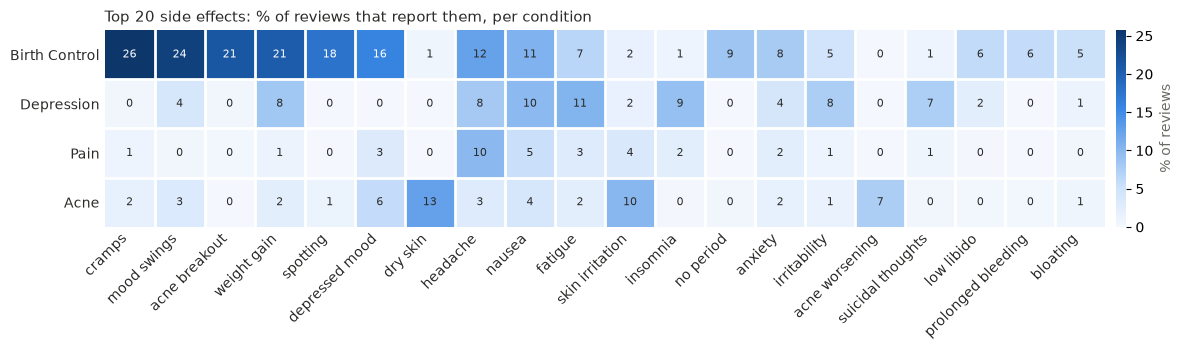

condition_name,Birth Control,Depression,Pain,Acne
basket,,,,
cramps,25.8,0.4,0.9,1.7
mood_swings,24.2,3.9,0.4,3.3
acne_breakout,21.2,0.4,0.3,0.0
weight_gain,20.5,8.3,1.1,2.3
spotting,17.7,0.0,0.0,1.1
depressed_mood,15.8,0.0,3.2,5.7
dry_skin,0.7,0.0,0.1,12.6
headache,12.5,8.0,9.9,3.1
nausea,10.7,9.8,5.4,3.9


In [12]:
def condition_concept_heatmap(baskets, top=20):
    # % of the condition's reviews that report each concept, top concepts by their maximum share
    pct = (baskets[['condition_name', 'basket']].explode('basket').dropna().value_counts().unstack(fill_value=0)
           .div(baskets['condition_name'].value_counts(), axis=0) * 100).reindex(CONDITIONS)
    columns = pct.max().sort_values(ascending=False).index[:top]
    pct = pct[columns]
    fig, ax = plt.subplots(figsize=(12, 3.6))
    image = ax.imshow(pct.values, cmap=BLUES, aspect='auto', vmin=0)
    ax.set_xticks(range(len(columns)), [c.replace('_', ' ') for c in columns], rotation=45, ha='right')
    ax.set_yticks(range(len(pct.index)), pct.index)
    for i in range(pct.shape[0]):
        for j in range(pct.shape[1]):
            value = pct.values[i, j]
            ax.text(j, i, f'{value:.0f}', ha='center', va='center', fontsize=8,
                    color='white' if value > pct.values.max() * 0.55 else INK)
    ax.set_xticks([x - 0.5 for x in range(1, len(columns))], minor=True)
    ax.set_yticks([y - 0.5 for y in range(1, len(pct.index))], minor=True)
    ax.grid(which='minor', color='white', linewidth=2)
    ax.tick_params(which='both', length=0, labelcolor=INK)
    for spine in ax.spines.values():
        spine.set_visible(False)
    bar = fig.colorbar(image, ax=ax, fraction=0.025, pad=0.01)
    bar.set_label('% of reviews', color=MUTED)
    bar.outline.set_visible(False)
    ax.set_title(f'Top {top} side effects: % of reviews that report them, per condition', loc='left', color=INK, fontsize=11)
    fig.tight_layout()
    return fig, pct.round(1)


fig, concept_share = condition_concept_heatmap(baskets, top=20)
save_figure(fig, 'condition_concept_heatmap.png')
run_stats['baskets']['top_concept_by_condition'] = {c: f'{concept_share.loc[c].idxmax()} ({concept_share.loc[c].max():.0f} %)' for c in CONDITIONS}
plt.show()
concept_share.T.head(10)

The profile of each condition is the expected one: menstrual effects and weight gain in Birth Control, nausea and sleep problems in Depression, drowsiness and nausea in Pain, dry skin and lips in Acne. 

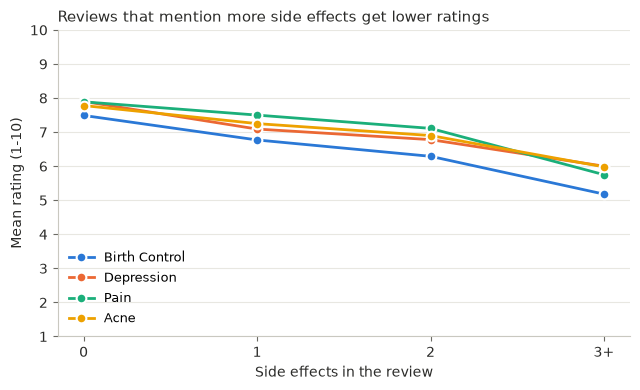

% of negative reviews


n_side_effects,0,1,2,3+
condition_name,,,,
Birth Control,7.49,6.77,6.29,5.18
Depression,7.90,7.09,6.78,6.00
Pain,7.89,7.50,7.11,5.75
Acne,7.78,7.25,6.90,5.98


In [ ]:
# mean rating and % of negative reviews by number of side effects
size_groups = baskets['n_items'].clip(upper=3).map(lambda n: '3+' if n == 3 else str(n))
rating_table = (baskets.assign(n_side_effects=size_groups, negative=baskets['rating'] <= NEGATIVE_RATING_MAX)
                .groupby(['condition_name', 'n_side_effects'])
                .agg(n_reviews=('review_id', 'size'), mean_rating=('rating', 'mean'), pct_negative=('negative', 'mean')))
rating_table['pct_negative'] *= 100
rating_table = rating_table.round(2).reset_index()


def rating_by_n_items_plot(rating_table):
    order = ['0', '1', '2', '3+']
    fig, ax = plt.subplots(figsize=(6.5, 4))
    for condition, colour in CONDITION_COLOURS.items():
        rows = rating_table[rating_table['condition_name'] == condition].set_index('n_side_effects').reindex(order)
        ax.plot(order, rows['mean_rating'], color=colour, linewidth=2, marker='o', markersize=7,
                markeredgecolor='white', markeredgewidth=1.5, label=condition)
    ax.set_xlabel('Side effects in the review', color=INK)
    ax.set_ylabel('Mean rating (1-10)', color=INK)
    ax.set_ylim(1, 10)
    clean_axes(ax)
    ax.legend(frameon=False, loc='lower left', fontsize=9)
    ax.set_title('Reviews that mention more side effects get lower ratings', loc='left', color=INK, fontsize=11)
    fig.tight_layout()
    return fig


fig = rating_by_n_items_plot(rating_table)
save_figure(fig, 'rating_by_n_side_effects.png')
plt.show()
print(f'% of negative reviews')
rating_by_size = rating_table.pivot(index='condition_name', columns='n_side_effects', values='mean_rating').reindex(CONDITIONS)
run_stats['baskets']['mean_rating_by_n_side_effects'] = rating_by_size.round(2).to_dict(orient='index')

It is also interesting to show that the most side effects mentioned by a review, the less rating it has, as shown in the figure.  

### Side-effect profile of every drug

In [14]:
concept_flags = pd.DataFrame([[c in set(b) for c in CONCEPTS] for b in baskets['basket']], columns=CONCEPTS, index=baskets.index)
grouped = pd.concat([baskets[['drug_family', 'condition_name']], concept_flags], axis=1).groupby(['drug_family', 'condition_name'])
drug_profiles = (grouped[CONCEPTS].mean() * 100).round(2)
drug_profiles.insert(0, 'n_reviews', grouped.size())
drug_profiles = drug_profiles.reset_index().sort_values(['condition_name', 'n_reviews'], ascending=[True, False])
drug_profiles.to_csv(OUTPUT_DIR / 'drug_side_effect_profiles.csv', index=False)
print(drug_profiles.shape, '(one row per drug family x condition; columns = % of its reviews that report the concept)')
drug_profiles.head()

(177, 60) (one row per drug family x condition; columns = % of its reviews that report the concept)


,drug_family,condition_name,n_reviews,weight_gain,weight_loss,increased_appetite,decreased_appetite,nausea,vomiting,diarrhea,...,palpitations,blurred_vision,muscle_joint_pain,blood_clots,high_blood_pressure,chest_pain,shortness_of_breath,allergic_reaction,withdrawal,dependence
92,Isotretinoin,Acne,682,0.29,0.44,0.15,0.15,0.44,0.29,0.15,...,0.15,1.17,6.89,0.0,0.15,0.73,0.15,0.59,0.0,0.0
63,Epiduo,Acne,547,0.00,0.00,0.00,0.00,0.00,0.18,0.00,...,0.00,0.00,0.00,0.0,0.00,0.00,0.00,1.28,0.0,0.0
58,Doxycycline,Acne,500,0.60,0.00,0.00,0.40,11.60,5.80,0.80,...,0.00,0.00,0.20,0.0,0.00,0.60,0.20,1.00,0.0,0.0
28,Benzoyl peroxide / clindamycin,Acne,354,0.00,0.28,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.0,0.00,0.00,0.00,2.26,0.0,0.0
112,Minocycline,Acne,333,0.30,0.30,0.00,0.00,9.31,2.10,1.80,...,0.00,0.60,3.00,0.0,0.30,0.90,0.60,3.30,0.0,0.0


## E6 · A-priori from scratch

A-priori avoids counting most of the possible pairs and triples based on  with one observation: *if an itemset is frequent, every subset of it is frequent* and, therefore, *a pair can only be frequent if both its items are frequent* and  *triple only if its three pairs are*. So each pass only counts candidates built from the frequent itemsets of the previous pass:

- **pass 1**: count every item → frequent items L1;
- **pass 2**: re-number the m frequent items 0..m−1 and count their pairs in a **triangular array** of m(m−1)/2 counters (4 bytes each, no dictionary); pair (i, j) with i < j is at position i·(2m − i − 1)/2 + j − i − 1 → L2;
- **pass 3**: candidate triples come from the *join* of two frequent pairs that share their first item, then the *prune* keeps a triple only if its three pairs are frequent; the survivors are counted in a dictionary → L3.

In order to do so, we will consider that an itemset is *frequent* when **it appears in at least 0.5 % of the reviews of his condition and a minimum of 20**. This decision is later discussed with several thresholds and count the frequent items, pairs and triples of each condition.


In [15]:
BYTES_PER_COUNT = 4          # one int32 counter


class PassMeter:
    """Time of one pass and, if tracemalloc is running, the extra peak memory it used."""

    def __enter__(self):
        self.tracing = tracemalloc.is_tracing()
        if self.tracing:
            tracemalloc.reset_peak()
            self.start_memory = tracemalloc.get_traced_memory()[0]
        self.start = time.perf_counter()
        return self

    def __exit__(self, *exc):
        self.seconds = time.perf_counter() - self.start
        self.peak_bytes = (tracemalloc.get_traced_memory()[1] - self.start_memory) if self.tracing else None
        return False


def pass_stats(k, n_candidates, n_frequent, n_bytes, meter, **extra):
    return {'pass': k, 'n_candidates': int(n_candidates), 'n_frequent': int(n_frequent),
            'bytes': int(n_bytes), 'seconds': meter.seconds, 'peak_bytes': meter.peak_bytes, **extra}


def prepare_baskets(baskets):
    # every basket as a sorted tuple without repeated items (the algorithms rely on i < j)
    return [tuple(sorted(set(int(i) for i in basket))) for basket in baskets]


def count_items(baskets, n_items):
    flat = np.fromiter(chain.from_iterable(baskets), dtype=np.int64)
    counts = np.bincount(flat, minlength=n_items)
    if len(counts) > n_items:
        raise ValueError('an item id is >= n_items')
    return counts.astype(np.int32)


def triangular_index(i, j, m):
    # position of the pair (i, j), 0 <= i < j < m, in an array of m(m-1)/2 counts (row i stored after row i-1)
    return i * (2 * m - i - 1) // 2 + j - i - 1


def triangular_pairs(positions, m):
    # inverse of triangular_index for an array of positions: returns (i, j)
    rows = np.arange(m, dtype=np.int64)
    row_start = rows * (2 * m - rows - 1) // 2
    i = np.searchsorted(row_start, positions, side='right') - 1
    j = positions - row_start[i] + i + 1
    return i, j


def candidate_itemsets(frequent, k):
    # C_k from L_{k-1}. Join: two frequent (k-1)-itemsets sharing their first k-2 items give a k-itemset.
    # Prune: keep it only if all its (k-1)-subsets are frequent (monotonicity).
    by_prefix = {}
    for itemset in sorted(frequent):
        by_prefix.setdefault(itemset[:-1], []).append(itemset[-1])
    candidates = set()
    for prefix, last_items in by_prefix.items():
        for x, y in combinations(last_items, 2):
            candidate = prefix + (x, y)
            if all(subset in frequent for subset in combinations(candidate, k - 1)):
                candidates.add(candidate)
    return candidates


def count_itemsets(baskets, candidates, k):
    # count the candidate k-itemsets in one pass over the baskets
    counts = dict.fromkeys(candidates, 0)
    useful_items = set(chain.from_iterable(candidates))
    for basket in baskets:
        items = [i for i in basket if i in useful_items]
        if len(items) < k:
            continue
        for itemset in combinations(items, k):
            if itemset in counts:
                counts[itemset] += 1
    return counts


def later_passes(baskets, frequent_pairs, min_count, max_k, itemsets, stats):
    # passes 3..max_k, shared by A-priori and PCY (they only differ in passes 1-2)
    frequent = set(frequent_pairs)
    for k in range(3, max_k + 1):
        with PassMeter() as meter:
            candidates = candidate_itemsets(frequent, k)
            counts = count_itemsets(baskets, candidates, k) if candidates else {}
            frequent_k = {s: c for s, c in counts.items() if c >= min_count}
        itemsets[k] = frequent_k
        stats.append(pass_stats(k, len(candidates), len(frequent_k), (k + 1) * BYTES_PER_COUNT * len(candidates), meter))
        if not frequent_k:
            break
        frequent = set(frequent_k)


def apriori(baskets, n_items, min_count, max_k=MAX_ITEMSET_SIZE):
    """All itemsets of size <= max_k in at least min_count baskets: ({k: {itemset: count}}, stats per pass)."""
    baskets = prepare_baskets(baskets)
    itemsets, stats = {}, []

    # Pass 1: count every item
    with PassMeter() as meter:
        item_counts = count_items(baskets, n_items)
        frequent_items = np.flatnonzero(item_counts >= min_count)
    itemsets[1] = {(int(i),): int(item_counts[i]) for i in frequent_items}
    stats.append(pass_stats(1, n_items, len(frequent_items), item_counts.nbytes, meter))

    if max_k >= 2:
        # Pass 2: re-number the m frequent items 0..m-1 and count their pairs in a triangular array
        with PassMeter() as meter:
            m = len(frequent_items)
            new_id = [-1] * n_items              # "frequent-items table" of the book
            for new, old in enumerate(frequent_items):
                new_id[old] = new
            triangle = np.zeros(m * (m - 1) // 2, dtype=np.int32)
            for basket in baskets:
                items = [new_id[i] for i in basket if new_id[i] >= 0]
                for i, j in combinations(items, 2):
                    triangle[i * (2 * m - i - 1) // 2 + j - i - 1] += 1
            positions = np.flatnonzero(triangle >= min_count)
            rows, cols = triangular_pairs(positions, m)
            frequent_pairs = {(int(frequent_items[i]), int(frequent_items[j])): int(triangle[p])
                              for i, j, p in zip(rows, cols, positions)}
        itemsets[2] = frequent_pairs
        stats.append(pass_stats(2, m * (m - 1) // 2, len(frequent_pairs), triangle.nbytes + BYTES_PER_COUNT * n_items,
                                meter, n_pairs_seen=int(np.count_nonzero(triangle))))
        del triangle
        later_passes(baskets, frequent_pairs, min_count, max_k, itemsets, stats)

    for k in range(1, max_k + 1):
        itemsets.setdefault(k, {})
    return itemsets, stats

# NO SE SI METERLO, NO ME GUSTA ESTO 
def brute_force_itemsets(baskets, min_count, max_k=MAX_ITEMSET_SIZE):
    # every combination of every basket, counted: slow but obviously right
    counts = Counter()
    for basket in prepare_baskets(baskets):
        for k in range(1, max_k + 1):
            counts.update(combinations(basket, k))
    return {k: {s: c for s, c in counts.items() if len(s) == k and c >= min_count} for k in range(1, max_k + 1)}


def itemsets_table(itemsets, n_baskets, condition, names=CONCEPTS):
    rows = [{'condition_name': condition, 'k': k, 'itemset': ' + '.join(names[i] for i in itemset),
             'count': count, 'support': count / n_baskets}
            for k, by_itemset in itemsets.items() for itemset, count in by_itemset.items()]
    return pd.DataFrame(rows, columns=['condition_name', 'k', 'itemset', 'count', 'support']).sort_values(
        ['k', 'count', 'itemset'], ascending=[True, False, True], ignore_index=True)   # itemset name breaks ties

### Decision of the support threshold 

In order to decide the support threshold, PCY was run with different thresholds, obtaining the following results. 

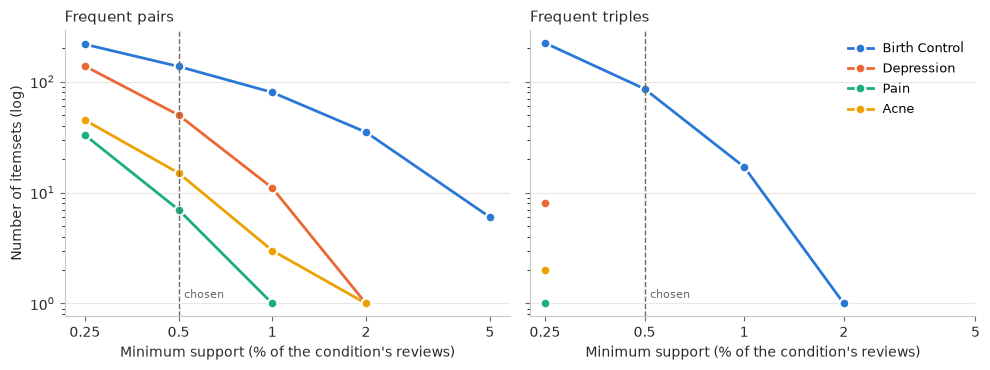

frequent_pairs                               frequent_triples                              
condition_name           Acne Birth Control Depression Pain             Acne Birth Control Depression Pain
min_support                                                                                               
0.0025                     45           217        138   33                2           223          8    1
0.0050                     15           137         50    7                0            86          0    0
0.0100                      3            80         11    1                0            17          0    0
0.0200                      1            35          1    0                0             1          0    0
0.0500                      0             6          0    0                0             0          0    0

In [16]:
def min_count_for(n_baskets, min_support=MIN_SUPPORT, floor=MIN_COUNT_FLOOR):
    # an itemset is frequent if at least this many reviews report it: relative to the size of the condition, with an absolute minimum
    return max(math.ceil(min_support * n_baskets), floor)


N_ITEMS = len(CONCEPTS)
baskets_by_condition = {c: baskets.loc[baskets['condition_name'] == c, 'basket_ids'].tolist() for c in CONDITIONS}

sensitivity_rows = []
for condition, data in baskets_by_condition.items():
    for support in SUPPORTS_TO_COMPARE:
        min_count = max(math.ceil(support * len(data)), 1)      # no floor here: we want to see the raw effect
        found, _ = apriori(data, N_ITEMS, min_count)
        sensitivity_rows.append({'condition_name': condition, 'min_support': support, 'min_count': min_count,
                                 'frequent_items': len(found[1]), 'frequent_pairs': len(found[2]), 'frequent_triples': len(found[3])})
sensitivity = pd.DataFrame(sensitivity_rows)


def support_sensitivity_plot(sensitivity, chosen):
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
    for ax, column, title in zip(axes, ['frequent_pairs', 'frequent_triples'], ['Frequent pairs', 'Frequent triples']):
        for condition, colour in CONDITION_COLOURS.items():
            rows = sensitivity[sensitivity['condition_name'] == condition]
            values = rows[column].where(rows[column] > 0)          # log scale: 0 is not drawn
            ax.plot(rows['min_support'] * 100, values, color=colour, linewidth=2, marker='o', markersize=7,
                    markeredgecolor='white', markeredgewidth=1.5, label=condition)
        ax.axvline(chosen * 100, color=MUTED, linestyle='--', linewidth=1)
        ax.annotate('chosen', (chosen * 100, 1), xytext=(4, 4), textcoords='offset points', color=MUTED, fontsize=8)
        plain_log_x(ax, [0.25, 0.5, 1, 2, 5], ['0.25', '0.5', '1', '2', '5'])
        ax.set_yscale('log')
        ax.set_xlabel("Minimum support (% of the condition's reviews)", color=INK)
        ax.set_title(title, loc='left', color=INK, fontsize=11)
        clean_axes(ax)
    axes[0].set_ylabel('Number of itemsets (log)', color=INK)
    axes[1].legend(frameon=False, fontsize=9)
    fig.tight_layout()
    return fig


fig = support_sensitivity_plot(sensitivity, chosen=MIN_SUPPORT)
save_figure(fig, 'support_sensitivity.png')
plt.show()
sensitivity_wide = sensitivity.pivot(index='min_support', columns='condition_name', values=['frequent_pairs', 'frequent_triples'])
run_stats['support_sensitivity'] = sensitivity.to_dict(orient='records')
sensitivity_wide

While with 1 % of the project guide, Pain is left with only a single frequent pair and Acne with three, at 0.25 % the counts explode (Birth Control: about 200 pairs and 200 triples). **With 0.5 %**,  every condition keeps enough pairs and, with the floor, every frequent itemset is reported by at least 20 reviews. This is the threshold used from here on: `min_count = max(0.5 % × N, 20)`.

### Run A-priori on the four conditions

In [17]:
frequent_itemsets, apriori_stats = {}, {}
for condition, data in baskets_by_condition.items():
    min_count = min_count_for(len(data))
    started = time.perf_counter()
    found, stats = apriori(data, N_ITEMS, min_count)
    seconds = time.perf_counter() - started
    assert found == brute_force_itemsets(data, min_count), f'A-priori differs from brute force on {condition}'
    frequent_itemsets[condition] = itemsets_table(found, len(data), condition)
    apriori_stats[condition] = stats
    print(f'{condition:14s} N = {len(data):6,}  min_count = {min_count:3d}  items / pairs / triples: '
          f'{len(found[1]):3d} / {len(found[2]):3d} / {len(found[3]):3d}   {seconds * 1000:.0f} ms, same as brute force')
frequent_itemsets = pd.concat(frequent_itemsets.values(), ignore_index=True)

itemset_counts = frequent_itemsets.groupby(['condition_name', 'k']).size().unstack(fill_value=0).reindex(CONDITIONS)
itemset_counts.columns = ['frequent_items', 'frequent_pairs', 'frequent_triples'][:len(itemset_counts.columns)]
run_stats['frequent_itemsets'] = {
    'min_support': MIN_SUPPORT, 'min_count_floor': MIN_COUNT_FLOOR,
    'min_count_by_condition': {c: min_count_for(len(d)) for c, d in baskets_by_condition.items()},
    'by_condition': itemset_counts.to_dict(orient='index'),
    'total': itemset_counts.sum().to_dict(),
}
itemset_counts

Birth Control  N = 19,520  min_count =  98  items / pairs / triples:  38 / 137 /  86   182 ms, same as brute force
Depression     N =  7,109  min_count =  36  items / pairs / triples:  33 /  50 /   0   47 ms, same as brute force
Pain           N =  5,187  min_count =  26  items / pairs / triples:  27 /   7 /   0   18 ms, same as brute force


Acne           N =  4,549  min_count =  23  items / pairs / triples:  28 /  15 /   0   28 ms, same as brute force


,frequent_items,frequent_pairs,frequent_triples
condition_name,,,
Birth Control,38,137,86
Depression,33,50,0
Pain,27,7,0
Acne,28,15,0


In [18]:
# the five most frequent pairs and triples of every condition
frequent_itemsets[frequent_itemsets['k'] >= 2].groupby(['condition_name', 'k']).head(5).round(4)

,condition_name,k,itemset,count,support
38,Birth Control,2,depressed_mood + mood_swings,1422,0.0728
39,Birth Control,2,weight_gain + mood_swings,1355,0.0694
40,Birth Control,2,mood_swings + acne_breakout,1259,0.0645
41,Birth Control,2,spotting + cramps,1226,0.0628
42,Birth Control,2,weight_gain + acne_breakout,1145,0.0587
175,Birth Control,3,weight_gain + mood_swings + acne_breakout,412,0.0211
176,Birth Control,3,weight_gain + depressed_mood + mood_swings,390,0.0200
177,Birth Control,3,depressed_mood + mood_swings + acne_breakout,362,0.0185
178,Birth Control,3,mood_swings + cramps + acne_breakout,317,0.0162
179,Birth Control,3,anxiety + depressed_mood + mood_swings,312,0.0160


 Birth Control, the largest condition, has by far the most pairs and triples (its side effects are many and often reported together: menstrual changes, weight, mood); Pain has the fewest. The most frequent pairs are plausible combinations (weight gain + mood swings, nausea + headache, dry skin + dry lips). 

## E7 · PCY from scratch

In pass 1 A-priori only counts items and leaves almost all the memory idle. PCY uses that memory: while reading the baskets in pass 1 it also **hashes every pair of the basket to one of B buckets** and counts the buckets. A bucket's count is the sum of the counts of all the pairs that fall in it, so **a pair in a bucket with count < min_count cannot be frequent**. Between passes the bucket counts become a **bitmap** (1 bit per bucket: frequent or not), and in pass 2 a pair is counted only if both items are frequent *and* its bucket is frequent. The candidates are now scattered, so they go in a dictionary (12 bytes per pair: two ids and a count) instead of the triangular array (4 bytes per pair): PCY only saves memory if the bitmap removes at least **2/3** of the pairs (the 2/3 rule, E8).


In [19]:
PRIME = 2_147_483_647        # 2^31 - 1
BYTES_PER_PAIR_ENTRY = 12     # two item ids + one count, in a dict


def hash_parameters(seed=RANDOM_SEED):
    rng = np.random.default_rng(seed)
    a, b = (int(x) for x in rng.integers(1, PRIME, size=2))
    return a, b


def pair_bucket(i, j, n_buckets, a, b):
    return ((a * i + b * j) % PRIME) % n_buckets


def bitmap_candidates(frequent_items, frequent_bucket, a, b, n_buckets):
    # how many of the m(m-1)/2 pairs of frequent items fall in a frequent bucket
    items = np.asarray(frequent_items, dtype=np.int64)
    total = 0
    for position in range(len(items) - 1):
        buckets = ((a * items[position] + b * items[position + 1:]) % PRIME) % n_buckets
        total += int(frequent_bucket[buckets].sum())
    return total


def pcy(baskets, n_items, min_count, n_buckets=N_BUCKETS, seed=RANDOM_SEED, max_k=MAX_ITEMSET_SIZE):
    """Same output as apriori(), plus bucket statistics in the stats of pass 2."""
    baskets = prepare_baskets(baskets)
    a, b = hash_parameters(seed)
    B = n_buckets
    itemsets, stats = {}, []

    # Pass 1: count items AND hash every pair to a bucket
    with PassMeter() as meter:
        item_counts = count_items(baskets, n_items)
        bucket_counts = np.zeros(B, dtype=np.int32)
        n_pairs_hashed = 0
        for basket in baskets:
            for i, j in combinations(basket, 2):
                bucket_counts[((a * i + b * j) % PRIME) % B] += 1
            n_pairs_hashed += len(basket) * (len(basket) - 1) // 2
        frequent_items = np.flatnonzero(item_counts >= min_count)
    itemsets[1] = {(int(i),): int(item_counts[i]) for i in frequent_items}
    stats.append(pass_stats(1, n_items, len(frequent_items), item_counts.nbytes + bucket_counts.nbytes, meter,
                            n_pairs_hashed=n_pairs_hashed))

    if max_k >= 2:
        with PassMeter() as meter:
            # Between passes: replace the bucket counts by a bitmap (1 bit per bucket)
            frequent_bucket = bucket_counts >= min_count
            bitmap = np.packbits(frequent_bucket)
            bits = bitmap.tobytes()
            del bucket_counts
            # Pass 2: count only the pairs that pass both filters
            is_frequent = [False] * n_items
            for i in frequent_items:
                is_frequent[i] = True
            pair_counts = {}
            for basket in baskets:
                items = [i for i in basket if is_frequent[i]]
                for i, j in combinations(items, 2):
                    h = ((a * i + b * j) % PRIME) % B
                    if bits[h >> 3] >> (7 - (h & 7)) & 1:      # bit h of the bitmap
                        pair_counts[(i, j)] = pair_counts.get((i, j), 0) + 1
            frequent_pairs = {pair: c for pair, c in pair_counts.items() if c >= min_count}

        # diagnostics (not timed)
        m = len(frequent_items)
        n_frequent_buckets = int(frequent_bucket.sum())
        buckets_with_frequent_pair = {pair_bucket(i, j, B, a, b) for i, j in frequent_pairs}
        candidates = bitmap_candidates(frequent_items, frequent_bucket, a, b, B)
        itemsets[2] = frequent_pairs
        stats.append(pass_stats(
            2, candidates, len(frequent_pairs),
            bitmap.nbytes + BYTES_PER_PAIR_ENTRY * len(pair_counts) + BYTES_PER_COUNT * n_items, meter,
            n_pairs_seen=len(pair_counts), apriori_candidates=m * (m - 1) // 2, n_buckets=B,
            n_frequent_buckets=n_frequent_buckets,
            false_positive_buckets=n_frequent_buckets - len(buckets_with_frequent_pair), bitmap_bytes=int(bitmap.nbytes)))
        later_passes(baskets, frequent_pairs, min_count, max_k, itemsets, stats)

    for k in range(1, max_k + 1):
        itemsets.setdefault(k, {})
    return itemsets, stats

### Check on the real data: PCY must give exactly the same itemsets as A-priori

In [20]:
pcy_check = []
for condition, data in baskets_by_condition.items():
    found, stats = pcy(data, N_ITEMS, min_count_for(len(data)), n_buckets=N_BUCKETS)
    table = itemsets_table(found, len(data), condition)
    same = table.equals(frequent_itemsets[frequent_itemsets['condition_name'] == condition].reset_index(drop=True))
    assert same, f'PCY differs from A-priori on {condition}'
    pass2 = stats[1]
    pcy_check.append({'condition_name': condition, 'same_itemsets_as_apriori': same,
                      'frequent_items_m': stats[0]['n_frequent'],
                      'apriori_candidate_pairs': pass2['apriori_candidates'], 'pcy_candidate_pairs': pass2['n_candidates'],
                      'pct_candidates_removed': round(100 * (1 - pass2['n_candidates'] / pass2['apriori_candidates']), 1),
                      'pct_frequent_buckets': round(100 * pass2['n_frequent_buckets'] / pass2['n_buckets'], 2),
                      'false_positive_buckets': pass2['false_positive_buckets']})
pcy_check = pd.DataFrame(pcy_check)
run_stats['pcy_check'] = pcy_check.to_dict(orient='records')
pcy_check

,condition_name,same_itemsets_as_apriori,frequent_items_m,apriori_candidate_pairs,pcy_candidate_pairs,pct_candidates_removed,pct_frequent_buckets,false_positive_buckets
0,Birth Control,True,38,703,137,80.5,1.37,0
1,Depression,True,33,528,50,90.5,0.50,0
2,Pain,True,27,351,7,98.0,0.07,0
3,Acne,True,28,378,15,96.0,0.15,0


**PCY returns exactly the same frequent itemsets as A-priori in the four conditions** (the assert passed), and its bitmap removes 80-98 % of the candidate pairs. However, whether the saved candidates are worth the extra hashing is the question of E8.

## E8 · Benchmark: A-priori vs PCY
**What we measure** for each dataset and algorithm:
- **time** per pass and total: median of `BENCHMARK_REPEATS` runs on the same machine (tracemalloc off, because tracing slows Python down);
- **memory of the counting structures**: the theoretical bytes (4 per counter in arrays, 12 per pair in the PCY dictionary, 1 bit per bucket) and the real peak per pass measured with `tracemalloc` in one extra run;
- **candidate pairs** of pass 2: m(m−1)/2 for A-priori, the pairs that pass the item and bitmap filters for PCY, and the % removed.

**Data.** The baskets of the four conditions, the same ones mined in E6 and E7.

**What to expect.** Our lexicon has 57 items, so A-priori's triangular array has at most 1,596 counters (a few KB). PCY attacks the memory of pass 2, which is only a problem when **many items are frequent** (thousands): there the triangular array grows as m²/2 and may not fit in memory. With 57 items PCY has nothing to save, so we expect it to be slower here; the benchmark measures by how much, and how well its filter works.

In [21]:
def run_algorithm(algorithm, baskets, n_items, min_count, n_buckets, max_k):
    if algorithm == 'apriori':
        return apriori(baskets, n_items, min_count, max_k=max_k)
    return pcy(baskets, n_items, min_count, n_buckets=n_buckets, max_k=max_k)


def benchmark(baskets, n_items, min_count, n_buckets, dataset, repeats=BENCHMARK_REPEATS, max_k=MAX_ITEMSET_SIZE):
    # one row per algorithm; also checks that both give the same itemsets
    baskets = prepare_baskets(baskets)
    rows, outputs = [], {}
    for algorithm in ('apriori', 'pcy'):
        seconds = []
        for _ in range(repeats):
            itemsets, stats = run_algorithm(algorithm, baskets, n_items, min_count, n_buckets, max_k)
            seconds.append([s['seconds'] for s in stats])
        tracemalloc.start()
        _, memory_stats = run_algorithm(algorithm, baskets, n_items, min_count, n_buckets, max_k)
        tracemalloc.stop()
        n_passes = min(len(s) for s in seconds)
        median = np.median([s[:n_passes] for s in seconds], axis=0)
        by_pass = {s['pass']: s for s in stats}
        peak = {s['pass']: s['peak_bytes'] for s in memory_stats}
        pass2 = by_pass.get(2, {})
        apriori_candidates = pass2.get('apriori_candidates', pass2.get('n_candidates'))
        rows.append({
            'dataset': dataset, 'algorithm': algorithm, 'n_baskets': len(baskets), 'n_items': n_items, 'min_count': min_count,
            'n_buckets': n_buckets if algorithm == 'pcy' else None,
            'frequent_items': len(itemsets[1]), 'frequent_pairs': len(itemsets[2]), 'frequent_triples': len(itemsets.get(3, {})),
            'pass1_seconds': median[0], 'pass2_seconds': median[1] if n_passes > 1 else np.nan,
            'pass3_seconds': median[2] if n_passes > 2 else np.nan, 'total_seconds': median.sum(),
            'pass1_bytes': by_pass[1]['bytes'], 'pass2_bytes': pass2.get('bytes'),
            'pass1_peak_bytes': peak.get(1), 'pass2_peak_bytes': peak.get(2),
            'pass2_candidates': pass2.get('n_candidates'), 'pass2_pairs_counted': pass2.get('n_pairs_seen'),
            'pct_candidates_removed': (100 * (1 - pass2['n_candidates'] / apriori_candidates)
                                       if algorithm == 'pcy' and apriori_candidates else 0.0),
            'pct_frequent_buckets': (100 * pass2['n_frequent_buckets'] / n_buckets if algorithm == 'pcy' and pass2 else np.nan),
            'false_positive_buckets': pass2.get('false_positive_buckets', np.nan),
        })
        outputs[algorithm] = itemsets
    same = outputs['apriori'] == outputs['pcy']
    for row in rows:
        row['same_itemsets'] = same
    return pd.DataFrame(rows)


def bucket_sweep(baskets, n_items, min_count, bucket_sizes, dataset):
    # effect of the number of buckets B on the PCY filter (one run per B, no timing)
    baskets = prepare_baskets(baskets)
    rows = []
    for n_buckets in bucket_sizes:
        _, stats = pcy(baskets, n_items, min_count, n_buckets=n_buckets)
        p2 = stats[1]
        rows.append({'dataset': dataset, 'n_buckets': n_buckets,
                     'pct_frequent_buckets': 100 * p2['n_frequent_buckets'] / n_buckets,
                     'false_positive_buckets': p2['false_positive_buckets'],
                     'apriori_candidates': p2['apriori_candidates'], 'pcy_candidates': p2['n_candidates'],
                     'pct_candidates_removed': 100 * (1 - p2['n_candidates'] / p2['apriori_candidates']) if p2['apriori_candidates'] else 0.0,
                     'pass2_bytes': p2['bytes'], 'apriori_pass2_bytes': 4 * p2['apriori_candidates'] + 4 * n_items})
    return pd.DataFrame(rows)

In [22]:
started = time.perf_counter()
real_benchmark = pd.concat([benchmark(data, N_ITEMS, min_count_for(len(data)), n_buckets=N_BUCKETS, dataset=condition)
                            for condition, data in baskets_by_condition.items()], ignore_index=True)
print(f'{time.perf_counter() - started:.0f} s')
real_benchmark[['dataset', 'algorithm', 'n_baskets', 'frequent_items', 'frequent_pairs', 'same_itemsets',
                'pass1_seconds', 'pass2_seconds', 'total_seconds', 'pass2_bytes', 'pass2_peak_bytes',
                'pass2_candidates', 'pct_candidates_removed']].round(4)

11 s


,dataset,algorithm,n_baskets,frequent_items,frequent_pairs,same_itemsets,pass1_seconds,pass2_seconds,total_seconds,pass2_bytes,pass2_peak_bytes,pass2_candidates,pct_candidates_removed
0,Birth Control,apriori,19520,38,137,True,0.0057,0.0876,0.1312,3040,21271,703,0.0000
1,Birth Control,pcy,19520,38,137,True,0.1077,0.1040,0.2476,3122,16650,137,80.5121
2,Depression,apriori,7109,33,50,True,0.0014,0.0135,0.0195,2340,8040,528,0.0000
3,Depression,pcy,7109,33,50,True,0.0174,0.0163,0.0384,2078,16650,50,90.5303
4,Pain,apriori,5187,27,7,True,0.0007,0.0052,0.0078,1632,3452,351,0.0000
5,Pain,pcy,5187,27,7,True,0.0065,0.0052,0.0137,1562,16594,7,98.0057
6,Acne,apriori,4549,28,15,True,0.0011,0.0098,0.0128,1740,4008,378,0.0000
7,Acne,pcy,4549,28,15,True,0.0070,0.0055,0.0142,1658,16594,15,96.0317


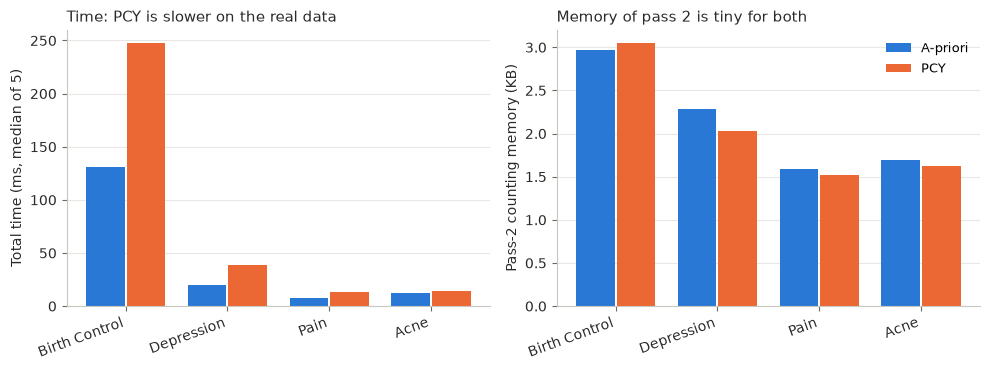

,dataset,n_buckets,pct_frequent_buckets,false_positive_buckets,apriori_candidates,pcy_candidates,pct_candidates_removed,pass2_bytes,apriori_pass2_bytes
0,Birth Control,100,99.00,18,703,697,0.85,8389,3040
1,Birth Control,1000,13.90,20,703,338,51.92,4373,3040
2,Birth Control,10000,1.37,0,703,137,80.51,3122,3040
3,Birth Control,100000,0.14,0,703,137,80.51,14372,3040


In [23]:
def grouped_bars(ax, table, column, scale=1.0):
    datasets = list(dict.fromkeys(table['dataset']))
    width = 0.38
    for offset, algorithm in zip((-width / 2 - 0.01, width / 2 + 0.01), ('apriori', 'pcy')):
        rows = table[table['algorithm'] == algorithm].set_index('dataset').reindex(datasets)
        ax.bar([x + offset for x in range(len(datasets))], rows[column] * scale, width=width,
               color=ALGORITHM_COLOURS[algorithm], label=ALGORITHM_NAMES[algorithm])
    ax.set_xticks(range(len(datasets)), datasets, rotation=20, ha='right')
    clean_axes(ax)


def benchmark_real_plot(table):
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
    grouped_bars(axes[0], table, 'total_seconds', scale=1000)
    axes[0].set_ylabel(f'Total time (ms, median of {BENCHMARK_REPEATS})', color=INK)
    axes[0].set_title('Time: PCY is slower on the real data', loc='left', color=INK, fontsize=11)
    grouped_bars(axes[1], table, 'pass2_bytes', scale=1 / 1024)
    axes[1].set_ylabel('Pass-2 counting memory (KB)', color=INK)
    axes[1].set_title('Memory of pass 2 is tiny for both', loc='left', color=INK, fontsize=11)
    axes[1].legend(frameon=False, fontsize=9)
    fig.tight_layout()
    return fig


fig = benchmark_real_plot(real_benchmark)
save_figure(fig, 'benchmark_real.png')
plt.show()

# effect of the number of buckets B on the largest condition
bc_data = baskets_by_condition['Birth Control']
real_sweep = bucket_sweep(bc_data, N_ITEMS, min_count_for(len(bc_data)), BUCKET_SIZES_REAL, dataset='Birth Control')
run_stats['benchmark_bucket_sweep'] = real_sweep.round(3).to_dict(orient='records')
real_sweep.round(2)

### PCY relative to A-priori, one row per condition

In [24]:
benchmark_table = real_benchmark
wide = benchmark_table.pivot(index='dataset', columns='algorithm')
comparison = pd.DataFrame({
    'frequent_items_m': wide[('frequent_items', 'apriori')],
    'same_itemsets': wide[('same_itemsets', 'apriori')],
    'apriori_ms': wide[('total_seconds', 'apriori')] * 1000,
    'pcy_ms': wide[('total_seconds', 'pcy')] * 1000,
    'time_pcy_vs_apriori': wide[('total_seconds', 'pcy')] / wide[('total_seconds', 'apriori')],
    'apriori_pass2_KB': wide[('pass2_bytes', 'apriori')] / 1024,
    'pcy_pass2_KB': wide[('pass2_bytes', 'pcy')] / 1024,
    'apriori_pass2_peak_KB': wide[('pass2_peak_bytes', 'apriori')] / 1024,
    'pcy_pass2_peak_KB': wide[('pass2_peak_bytes', 'pcy')] / 1024,
    'pct_candidates_removed_by_pcy': wide[('pct_candidates_removed', 'pcy')],
}).reindex(CONDITIONS)

run_stats['benchmark'] = {
    'repeats': BENCHMARK_REPEATS, 'n_buckets': N_BUCKETS, 'same_itemsets_everywhere': bool(comparison['same_itemsets'].all()),
    'pcy_time_ratio_median': round(float(comparison['time_pcy_vs_apriori'].median()), 2),
    'pct_candidates_removed_range': [round(float(comparison['pct_candidates_removed_by_pcy'].min()), 1),
                                     round(float(comparison['pct_candidates_removed_by_pcy'].max()), 1)],
    'apriori_pass2_KB_max': round(float(comparison['apriori_pass2_KB'].max()), 1),
    'table': comparison.round(3).reset_index().to_dict(orient='records'),
}
print(f"Same itemsets in every condition: {comparison['same_itemsets'].all()}")
print(f"PCY is {comparison['time_pcy_vs_apriori'].median():.1f}x slower (median over the conditions), removes "
      f"{comparison['pct_candidates_removed_by_pcy'].min():.0f}-{comparison['pct_candidates_removed_by_pcy'].max():.0f} % of the candidate pairs; "
      f"pass-2 counting memory is at most {comparison['apriori_pass2_KB'].max():.1f} KB for A-priori")
comparison.round(2)

Same itemsets in every condition: True
PCY is 1.8x slower (median over the conditions), removes 81-98 % of the candidate pairs; pass-2 counting memory is at most 3.0 KB for A-priori


,frequent_items_m,same_itemsets,apriori_ms,pcy_ms,time_pcy_vs_apriori,apriori_pass2_KB,pcy_pass2_KB,apriori_pass2_peak_KB,pcy_pass2_peak_KB,pct_candidates_removed_by_pcy
dataset,,,,,,,,,,
Birth Control,38,True,131.23,247.56,1.89,2.97,3.05,20.77,16.26,80.51
Depression,33,True,19.51,38.36,1.97,2.29,2.03,7.85,16.26,90.53
Pain,27,True,7.84,13.68,1.74,1.59,1.53,3.37,16.21,98.01
Acne,28,True,12.81,14.23,1.11,1.70,1.62,3.91,16.21,96.03


**Result: which algorithm, and when does PCY pay off?**

- **Both are exact.** A-priori and PCY return the same frequent itemsets in every condition (`same_itemsets`). The choice is only about time and memory.
- **On our data A-priori is the better choice.** With 57 items the triangular array of pass 2 is a few KB. PCY's filter works (it removes most of the candidate pairs) but there is nothing to save: pass-2 memory is about the same, PCY needs an extra bucket array in pass 1 (40 KB for 10,000 buckets) and it is slower, because pass 1 hashes every pair of every basket.
- **When PCY would pay off.** PCY only helps when the triangular array of pass 2 does not fit in memory, which needs thousands of frequent items (m²/2 counters: 10,000 frequent items are 200 MB). Even then it must remove at least **2/3** of the candidate pairs, because a pair in its dictionary costs 12 bytes vs 4 in the triangular array (the 2/3 rule of the book).
- **The number of buckets B matters** (bucket table above): with too few buckets almost every bucket is frequent and the filter removes nothing; more buckets filter more but cost memory (1 bit each in the bitmap).
- **Part of PCY's time cost is Python's.** Hashing a pair in pure Python costs about as much as counting it; in a compiled implementation the hash is almost free next to reading the data.

**Decision for the project.** The results use A-priori (simpler and faster here); PCY is reported as a validated alternative.

## E9 · Association rules
A pair can be frequent if it is reported in many reviews, but if both effects are common separately, they can be frequent by pure coincidente. In order to adress if this is because of pure luck or not, we introduce the following concepts in order to perform the test of Fisher and Benjamini-Hochberg. 

From every frequent pair and triple we form rules **X → Y** (X and Y non-empty and disjoint; a pair gives 2 rules, a triple 6). With N = all reviews of the condition, empty baskets included:

| Measure | Formula | Meaning |
|---|---|---|
| support | count(X ∪ Y) / N | share of all reviews that report both |
| confidence | count(X ∪ Y) / count(X) | of the patients who report X, the share who also report Y |
| lift | confidence / (count(Y) / N) | how many times more likely Y is given X than in general; > 1 = together more often than by chance (symmetric in X and Y) |
| interest | confidence − count(Y) / N | the book's measure: confidence minus what it would be by chance |


We rank **by lift**, not confidence: very common effects (fatigue, headache) have a high confidence with almost anything just because they are common, and lift corrects for that. 

However, in order to check if a value of lift is high by chance, we perform a one-sided **Fisher exact test** on the 2×2 table for each pair of frequent conditions (a total of 934 tests). In orther to do that much tests, and the p-values of all combinations are corrected for **Benjamini-Hochberg**, which controls the share of false discoveries among the rules we keep. Kept rules: count ≥ 20, confidence ≥ 0.1, lift > 1 and q < 0.05.

In [25]:
def benjamini_hochberg(p_values):
    # q-values of Benjamini & Hochberg (1995): q_(i) = min over j >= i of p_(j) * n / j
    p = np.asarray(p_values, dtype=float)
    n = len(p)
    if n == 0:
        return p
    order = np.argsort(p)
    scaled = p[order] * n / np.arange(1, n + 1)
    q_sorted = np.minimum.accumulate(scaled[::-1])[::-1]
    q = np.empty(n)
    q[order] = np.minimum(q_sorted, 1.0)
    return q


def fisher_greater(n_xy, n_x, n_y, n):
    # one-sided Fisher test on the 2x2 table X present/absent x Y present/absent
    table = [[n_xy, n_x - n_xy], [n_y - n_xy, n - n_x - n_y + n_xy]]
    return fisher_exact(table, alternative='greater').pvalue


def generate_rules(itemsets, n_baskets):
    # every rule X -> Y from the frequent itemsets of size >= 2 (the counts of X and Y are in `itemsets` by monotonicity)
    rows = []
    for k in sorted(itemsets):
        if k < 2:
            continue
        for itemset, n_xy in itemsets[k].items():
            for size in range(1, k):
                for antecedent in combinations(itemset, size):
                    consequent = tuple(i for i in itemset if i not in antecedent)
                    n_x, n_y = itemsets[len(antecedent)][antecedent], itemsets[len(consequent)][consequent]
                    confidence, p_y = n_xy / n_x, n_y / n_baskets
                    rows.append({'antecedent': antecedent, 'consequent': consequent, 'k': k, 'count': n_xy,
                                 'n_antecedent': n_x, 'n_consequent': n_y, 'support': n_xy / n_baskets,
                                 'confidence': confidence, 'lift': confidence / p_y, 'interest': confidence - p_y})
    return rows


def condition_rules(baskets_by_condition):
    # rules of every condition with p-values, q-values (BH over all tested rules) and filter flags; plus the filter funnel
    tables = []
    for condition, data in baskets_by_condition.items():
        n = len(data)
        found, _ = apriori(data, N_ITEMS, min_count_for(n))
        table = pd.DataFrame(generate_rules(found, n))
        table.insert(0, 'condition_name', condition)
        table.insert(1, 'drug_family', 'ALL')
        table['p_value'] = [fisher_greater(r.count, r.n_antecedent, r.n_consequent, n) for r in table.itertuples()]
        tables.append(table)
    rules = pd.concat(tables, ignore_index=True)

    tested = rules['count'] >= MIN_RULE_COUNT
    rules['q_value'] = np.nan
    rules.loc[tested, 'q_value'] = benjamini_hochberg(rules.loc[tested, 'p_value'])
    rules['kept'] = tested & (rules['confidence'] >= MIN_CONFIDENCE) & (rules['lift'] > MIN_LIFT) & (rules['q_value'] < FDR)
    rules['itemset'] = [' + '.join(CONCEPTS[i] for i in sorted(x + y)) for x, y in zip(rules['antecedent'], rules['consequent'])]
    for side in ('antecedent', 'consequent'):
        rules[side] = rules[side].map(lambda ids: ' + '.join(CONCEPTS[i] for i in ids))

    steps = [('all rules from frequent pairs and triples', pd.Series(True, index=rules.index)),
             (f'count(X u Y) >= {MIN_RULE_COUNT}', tested),
             (f'+ confidence >= {MIN_CONFIDENCE}', tested & (rules['confidence'] >= MIN_CONFIDENCE)),
             (f'+ lift > {MIN_LIFT:g}', tested & (rules['confidence'] >= MIN_CONFIDENCE) & (rules['lift'] > MIN_LIFT)),
             (f'+ q < {FDR} (Fisher + Benjamini-Hochberg)', rules['kept'])]
    funnel = pd.DataFrame({label: mask.groupby(rules['condition_name']).sum() for label, mask in steps}).T[CONDITIONS]
    funnel['total'] = funnel.sum(axis=1)
    columns = ['condition_name', 'drug_family', 'itemset', 'antecedent', 'consequent', 'k', 'count', 'n_antecedent',
               'n_consequent', 'support', 'confidence', 'lift', 'interest', 'p_value', 'q_value', 'kept']
    return rules[columns].sort_values(['condition_name', 'kept', 'lift'], ascending=[True, False, False], ignore_index=True), funnel


rules, rule_funnel = condition_rules(baskets_by_condition)
run_stats['rules'] = {'n_rules': int(len(rules)), 'n_rules_kept': int(rules['kept'].sum()),
                      'funnel': rule_funnel.astype(int).to_dict(orient='index'),
                      'kept_by_condition': rules[rules['kept']].groupby('condition_name').size().reindex(CONDITIONS).to_dict()}
print(f'{len(rules)} rules, {rules["kept"].sum()} kept')
print('How many rules survive each filter:')
rule_funnel

934 rules, 391 kept
How many rules survive each filter:


condition_name,Birth Control,Depression,Pain,Acne,total
all rules from frequent pairs and triples,790,100,14,30,934
count(X u Y) >= 20,790,100,14,30,934
+ confidence >= 0.1,440,57,11,22,530
+ lift > 1,357,55,11,20,443
+ q < 0.05 (Fisher + Benjamini-Hochberg),313,49,10,19,391


In [26]:
# worked example: the most frequent Birth Control pair, by hand
example = rules[(rules['condition_name'] == 'Birth Control') & (rules['k'] == 2)].sort_values('count', ascending=False).iloc[0]
N = len(baskets_by_condition['Birth Control'])
print(f'Birth Control, N = {N:,} reviews. X = {example["antecedent"]}: {example["n_antecedent"]:,} reviews; '
      f'Y = {example["consequent"]}: {example["n_consequent"]:,} reviews; both: {example["count"]:,} reviews.')
print(f'  support    = {example["count"]:,} / {N:,} = {example["count"] / N:.3f}')
print(f'  confidence = {example["count"]:,} / {example["n_antecedent"]:,} = {example["count"] / example["n_antecedent"]:.3f}')
print(f'  lift       = {example["count"] / example["n_antecedent"]:.3f} / ({example["n_consequent"]:,} / {N:,}) = '
      f'{example["count"] / example["n_antecedent"] / (example["n_consequent"] / N):.2f}')
print(f'  Fisher one-sided p = {example["p_value"]:.2e}, q = {example["q_value"]:.2e}, kept = {example["kept"]}')
run_stats['rules']['worked_example'] = example[['condition_name', 'antecedent', 'consequent', 'count', 'n_antecedent',
                                                'n_consequent', 'support', 'confidence', 'lift', 'q_value']].to_dict()

Birth Control, N = 19,520 reviews. X = mood_swings: 4,717 reviews; Y = depressed_mood: 3,088 reviews; both: 1,422 reviews.
  support    = 1,422 / 19,520 = 0.073
  confidence = 1,422 / 4,717 = 0.301
  lift       = 0.301 / (3,088 / 19,520) = 1.91
  Fisher one-sided p = 1.50e-188, q = 3.50e-186, kept = True


In [27]:
# top 10 rules by lift per condition (kept rules only)
top_rules = rules[rules['kept']].groupby('condition_name').head(10)
run_stats['rules']['top_rules_by_lift'] = top_rules[['condition_name', 'antecedent', 'consequent', 'count', 'confidence', 'lift']].round(3).to_dict(orient='records')
top_rules[['condition_name', 'antecedent', 'consequent', 'count', 'support', 'confidence', 'lift', 'q_value']].round(4)

,condition_name,antecedent,consequent,count,support,confidence,lift,q_value
0,Acne,nausea,vomiting,28,0.0062,0.1573,11.1808,0.0000
1,Acne,vomiting,nausea,28,0.0062,0.4375,11.1808,0.0000
2,Acne,anxiety,depressed_mood,38,0.0084,0.5067,8.8308,0.0000
3,Acne,depressed_mood,anxiety,38,0.0084,0.1456,8.8308,0.0000
4,Acne,muscle_joint_pain,dry_lips,25,0.0055,0.4167,8.7346,0.0000
5,Acne,dry_lips,muscle_joint_pain,25,0.0055,0.1152,8.7346,0.0000
6,Acne,nausea,headache,41,0.0090,0.2303,7.4312,0.0000
7,Acne,headache,nausea,41,0.0090,0.2908,7.4312,0.0000
8,Acne,depressed_mood,mood_swings,46,0.0101,0.1762,5.3808,0.0000
9,Acne,mood_swings,depressed_mood,46,0.0101,0.3087,5.3808,0.0000


**Result.** 391 of the 934 rules are kept. Most rules fall at the lift filter (both effects common, but not together more than by chance) and the significance test removes a further batch of weak rules with small counts. The strongest rules are clusters of related effects: menstrual effects together in Birth Control (spotting, prolonged bleeding, cramps), sexual effects and emotional numbness in Depression, drowsiness and dizziness in Pain, dry lips and dry skin in Acne. The rules are **symmetric descriptions of co-occurrence**, not causes: a high lift of nausea → vomiting says that patients who report one tend to report the other.

### Co-occurrence networks
One network per condition, made with the pairs of the rules above: nodes are side effects (size = % of reviews), edges the pairs with lift > 1.5 and q < 0.05 (width = lift). It describes each condition as a whole, not each drug.

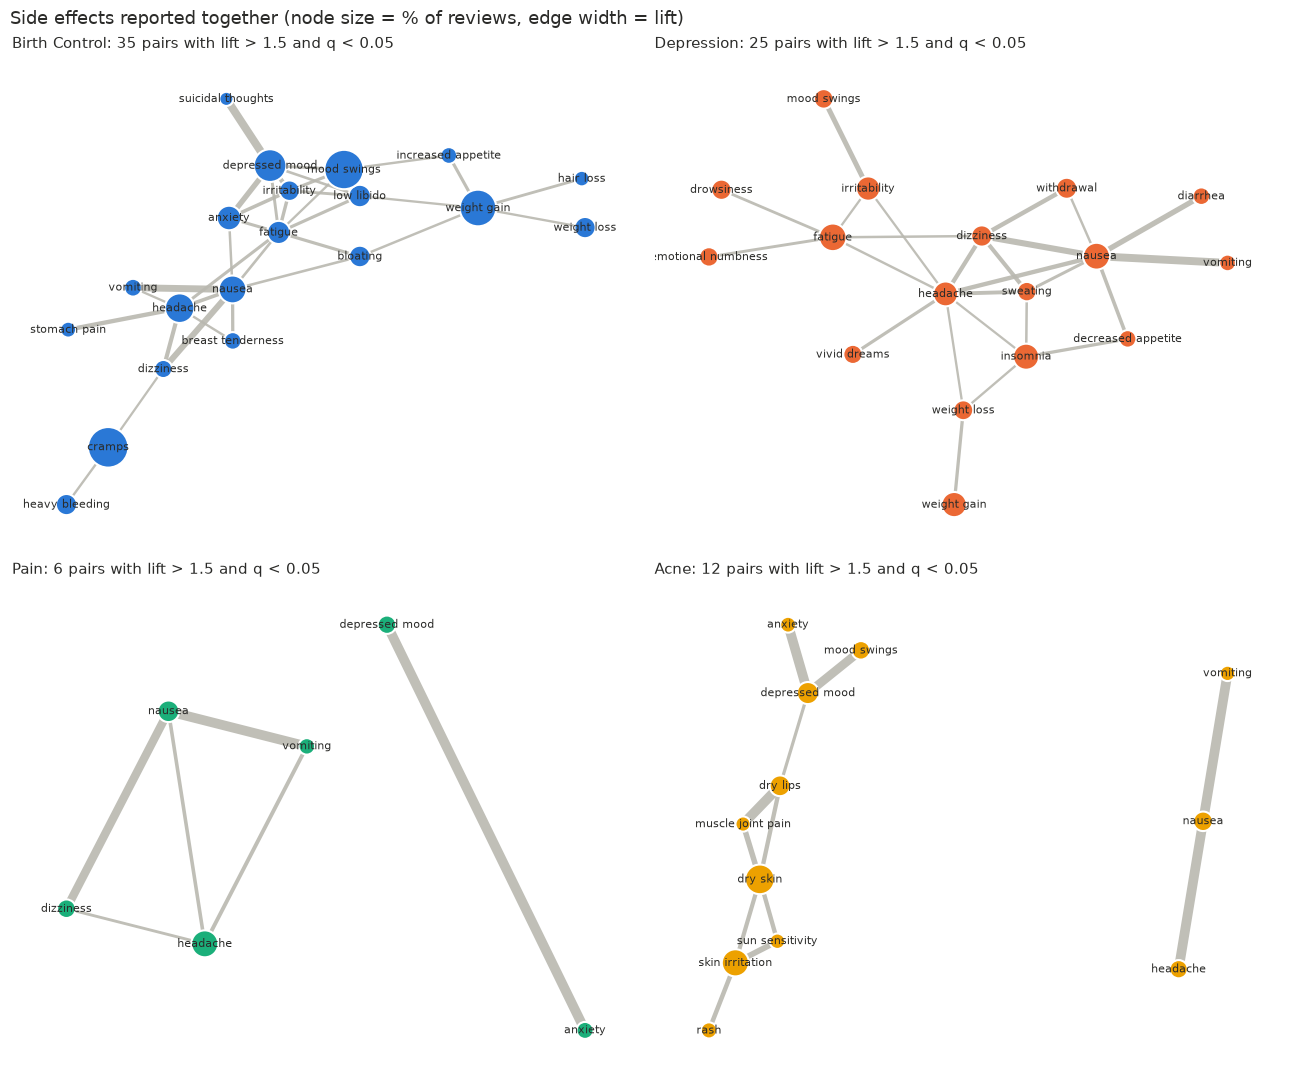

In [28]:
# pairs of the rules of every condition (also the starting point of E10)
pair_rules = rules[rules['k'] == 2].drop_duplicates(['condition_name', 'itemset'])
condition_pairs = pair_rules[['condition_name', 'itemset', 'count', 'support', 'lift', 'q_value', 'kept']].rename(columns={'itemset': 'pair'})


def cooccurrence_networks(condition_pairs, baskets, min_lift=NETWORK_MIN_LIFT):
    import networkx as nx
    fig, axes = plt.subplots(2, 2, figsize=(13, 11))
    for ax, condition in zip(axes.flat, CONDITION_COLOURS):
        n = (baskets['condition_name'] == condition).sum()
        item_share = baskets[baskets['condition_name'] == condition]['basket'].explode().value_counts() / n
        edges = condition_pairs[(condition_pairs['condition_name'] == condition) & (condition_pairs['lift'] > min_lift)
                                & (condition_pairs['q_value'] < FDR)]
        graph = nx.Graph()
        for row in edges.itertuples():
            a, b = row.pair.split(' + ')
            graph.add_edge(a, b, lift=row.lift)
        ax.set_title(f'{condition}: {graph.number_of_edges()} pairs with lift > {min_lift:g} and q < {FDR}', loc='left', color=INK, fontsize=11)
        ax.axis('off')
        if graph.number_of_nodes() == 0:
            continue
        layout, x_offset = {}, 0.0        # every connected group on its own, side by side
        for component in sorted(nx.connected_components(graph), key=len, reverse=True):
            sub = graph.subgraph(component)
            pos = nx.spring_layout(sub, seed=RANDOM_SEED, k=2.0 / np.sqrt(len(component)), weight=None, iterations=300)
            points = np.array(list(pos.values()))
            points = points - points.mean(axis=0)
            spread = np.abs(points).max() or 1.0
            width = 0.6 + 0.45 * np.sqrt(len(component))
            for node, point in zip(pos, points):
                layout[node] = point / spread * width / 2 + np.array([x_offset + width / 2, 0])
            x_offset += width + 0.5
        widths = [min(1 + 1.2 * (graph[a][b]['lift'] - 1), 7) for a, b in graph.edges]
        nx.draw_networkx_edges(graph, layout, ax=ax, width=widths, edge_color='#b9b8b0', alpha=0.9)
        nx.draw_networkx_nodes(graph, layout, ax=ax, node_size=[3000 * item_share.get(v, 0) + 80 for v in graph.nodes],
                               node_color=CONDITION_COLOURS[condition], edgecolors='white', linewidths=1.5)
        nx.draw_networkx_labels(graph, layout, ax=ax, labels={v: v.replace('_', ' ') for v in graph.nodes}, font_size=8, font_color=INK)
    fig.suptitle('Side effects reported together (node size = % of reviews, edge width = lift)', x=0.01, ha='left', color=INK, fontsize=13)
    fig.tight_layout()
    return fig


try:
    fig = cooccurrence_networks(condition_pairs, baskets)
    save_figure(fig, 'cooccurrence_networks.png')
    plt.show()
except ImportError:
    print('networkx is not installed: the co-occurrence networks are skipped (pip install networkx)')

## E10 · Do the combinations differ between drugs? (research question 2)
Mining every drug separately would leave too few reviews per drug, so we take the **pairs that are frequent at condition level** and measure them inside every drug with at least `MIN_REVIEWS_PER_DRUG` = 200 reviews in that condition:
1. support, confidence and lift of the pair *inside the drug*;
2. a two-sided **Fisher test** (2×2 table) of the co-occurrence rate in the drug vs the other drugs of the same condition, with Benjamini-Hochberg over all drug × pair tests.

Then, among the pairs that travel together at condition level (kept rules of E9):
- **universal**: lift > 1 in every eligible drug of the condition, the combination belongs to the condition (or to the drug class), not to one medicine;
- **drug-specific**: reported together significantly more often with one drug than with the other drugs (q < 0.05, odds ratio > 1). A pair can be both.

A pair can be *more frequent* with a drug only because one of its two effects is common with that drug (isotretinoin: depressed mood + dry lips, which do not go together inside the drug). The column `lift_other_drugs` next to `lift` shows whether the association itself is stronger in the drug, and the figure of drug-specific pairs adds a third filter: the pair must also go together **inside** the drug (one-sided Fisher within the drug, q < 0.05).

In [29]:
def drug_pair_rules(baskets, condition, pairs, min_reviews=MIN_REVIEWS_PER_DRUG):
    # condition-level pairs measured inside every drug with >= min_reviews reviews of the condition
    data = baskets[baskets['condition_name'] == condition]
    drug_sizes = data['drug_family'].value_counts()
    drugs = drug_sizes[drug_sizes >= min_reviews].index
    drug_of_review = data['drug_family'].to_numpy()
    basket_sets = [set(b) for b in data['basket']]
    rows = []
    for a, b in pairs:
        has_a = np.array([a in s for s in basket_sets])
        has_b = np.array([b in s for s in basket_sets])
        both = has_a & has_b
        for drug in drugs:
            in_drug = drug_of_review == drug
            n, n_a, n_b, n_ab = in_drug.sum(), has_a[in_drug].sum(), has_b[in_drug].sum(), both[in_drug].sum()
            rest = ~in_drug
            n_rest, n_ab_rest = rest.sum(), both[rest].sum()
            n_a_rest, n_b_rest = has_a[rest].sum(), has_b[rest].sum()
            odds_ratio, p_value = fisher_exact([[n_ab, n - n_ab], [n_ab_rest, n_rest - n_ab_rest]])
            rows.append({'condition_name': condition, 'drug_family': drug, 'pair': f'{a} + {b}', 'concept_a': a, 'concept_b': b,
                         'n_reviews': int(n), 'count_a': int(n_a), 'count_b': int(n_b), 'count': int(n_ab), 'support': n_ab / n,
                         'confidence_a_to_b': n_ab / n_a if n_a else np.nan, 'confidence_b_to_a': n_ab / n_b if n_b else np.nan,
                         'lift': n_ab * n / (n_a * n_b) if n_a and n_b else np.nan,
                         'support_other_drugs': n_ab_rest / n_rest if n_rest else np.nan,
                         'lift_other_drugs': n_ab_rest * n_rest / (n_a_rest * n_b_rest) if n_a_rest and n_b_rest else np.nan,
                         'odds_ratio_vs_other_drugs': odds_ratio, 'p_value': p_value})
    return pd.DataFrame(rows)


def classify_pairs(drug_rules, condition_pairs):
    # universal / drug-specific / both / neither, for the pairs associated at condition level
    associated = set(map(tuple, condition_pairs.loc[condition_pairs['kept'], ['condition_name', 'pair']].values))
    rows = []
    for (condition, pair), group in drug_rules.groupby(['condition_name', 'pair']):
        more = group[(group['q_value'] < FDR) & (group['odds_ratio_vs_other_drugs'] > 1)]
        less = group[(group['q_value'] < FDR) & (group['odds_ratio_vs_other_drugs'] < 1)]
        universal = bool((group['lift'] > 1).all())
        if (condition, pair) not in associated:
            label = 'not associated'
        elif universal:
            label = 'universal + drug-specific' if len(more) else 'universal'
        else:
            label = 'drug-specific' if len(more) else 'associated, neither'
        rows.append({'condition_name': condition, 'pair': pair, 'n_drugs': len(group),
                     'drugs_with_lift_above_1': int((group['lift'] > 1).sum()),
                     'min_lift_in_a_drug': group['lift'].min(), 'max_lift_in_a_drug': group['lift'].max(), 'universal': universal,
                     'more_frequent_in': ', '.join(more.sort_values('odds_ratio_vs_other_drugs', ascending=False)['drug_family']),
                     'less_frequent_in': ', '.join(less['drug_family']), 'category': label})
    return pd.DataFrame(rows).merge(condition_pairs, on=['condition_name', 'pair'], how='left')


# condition_pairs (one row per pair of the rules of E9) was defined in the co-occurrence networks cell of E9

drug_rules = pd.concat([
    drug_pair_rules(baskets, condition,
                    [tuple(p.split(' + ')) for p in condition_pairs.loc[condition_pairs['condition_name'] == condition, 'pair']])
    for condition in CONDITIONS], ignore_index=True)
drug_rules['q_value'] = benjamini_hochberg(drug_rules['p_value'])
pair_classes = classify_pairs(drug_rules, condition_pairs)

kept_classes = pair_classes[pair_classes['kept']]
class_counts = pair_classes.groupby(['condition_name', 'category']).size().unstack(fill_value=0).reindex(CONDITIONS)
run_stats['drug_comparison'] = {
    'min_reviews_per_drug': MIN_REVIEWS_PER_DRUG,
    'n_drugs_by_condition': drug_rules.groupby('condition_name')['drug_family'].nunique().reindex(CONDITIONS).to_dict(),
    'n_tests': int(len(drug_rules)), 'n_significant': int((drug_rules['q_value'] < FDR).sum()),
    'n_pairs_associated': int(len(kept_classes)),
    'n_universal_pairs': int(kept_classes['category'].str.startswith('universal').sum()),
    'n_drug_specific_pairs': int(kept_classes['category'].str.contains('drug-specific').sum()),
    'categories_by_condition': class_counts.to_dict(orient='index'),
}
print(f"{len(drug_rules)} drug x pair tests in {drug_rules['drug_family'].nunique()} drugs, {(drug_rules['q_value'] < FDR).sum()} significant")
print(f"{len(kept_classes)} pairs associated at condition level: {run_stats['drug_comparison']['n_universal_pairs']} universal "
      f"(incl. 'universal + drug-specific'), {run_stats['drug_comparison']['n_drug_specific_pairs']} drug-specific (incl. both)")
class_counts

2443 drug x pair tests in 39 drugs, 550 significant
127 pairs associated at condition level: 22 universal (incl. 'universal + drug-specific'), 98 drug-specific (incl. both)


category,"associated, neither",drug-specific,not associated,universal,universal + drug-specific
condition_name,,,,,
Birth Control,9,46,63,4,15
Depression,11,23,15,0,1
Pain,4,0,1,1,1
Acne,0,12,3,0,0


### Universal pairs: pairs that apper in all the drugs

In [30]:
# universal pairs: they travel together in every drug of the condition
kept_classes[kept_classes['universal']].sort_values(['condition_name', 'count'], ascending=[True, False])[
    ['condition_name', 'pair', 'count', 'lift', 'min_lift_in_a_drug', 'max_lift_in_a_drug', 'more_frequent_in']].round(2)

,condition_name,pair,count,lift,min_lift_in_a_drug,max_lift_in_a_drug,more_frequent_in
39,Birth Control,depressed_mood + mood_swings,1422,1.91,1.44,5.60,"Yaz, Ethinyl estradiol / norgestimate, Nexplanon"
138,Birth Control,weight_gain + mood_swings,1355,1.40,1.12,6.15,"Nexplanon, Medroxyprogesterone, Desogestrel / ethinyl estradiol"
83,Birth Control,mood_swings + acne_breakout,1259,1.26,1.02,4.17,"Yaz, Desogestrel / ethinyl estradiol, Ethinyl estradiol / norgestimate, Ethinyl estradiol / levonorgestrel, Ethinyl estradiol / norethindrone"
124,Birth Control,weight_gain + acne_breakout,1145,1.35,1.10,4.27,"Desogestrel / ethinyl estradiol, Nexplanon"
17,Birth Control,anxiety + depressed_mood,814,3.40,2.67,7.30,"Yaz, Nexplanon, Ethinyl estradiol / norgestimate"
102,Birth Control,nausea + headache,609,2.33,1.66,5.19,"Ethinyl estradiol / norelgestromin, Ethinyl estradiol / norgestimate, Ethinyl estradiol / levonorgestrel, Ethinyl estradiol / norethindrone"
20,Birth Control,anxiety + mood_swings,536,1.47,1.16,3.04,"Yaz, Ethinyl estradiol / norethindrone, Nexplanon"
89,Birth Control,mood_swings + irritability,443,2.05,1.37,4.98,
37,Birth Control,depressed_mood + irritability,400,2.83,1.59,11.08,Desogestrel / ethinyl estradiol
51,Birth Control,fatigue + depressed_mood,393,1.93,1.15,4.44,Nexplanon


### Drugs that appear only in an specific drug

In [31]:
# drug-specific pairs: significantly more frequent with one drug than with the rest of the condition (top 5 per condition)
specific = drug_rules.merge(condition_pairs.loc[condition_pairs['kept'], ['condition_name', 'pair']], on=['condition_name', 'pair'])
specific = specific[(specific['q_value'] < FDR) & (specific['odds_ratio_vs_other_drugs'] > 1)]
specific.sort_values('odds_ratio_vs_other_drugs', ascending=False).groupby('condition_name').head(5)[
    ['condition_name', 'drug_family', 'pair', 'n_reviews', 'count', 'support', 'support_other_drugs',
     'lift', 'lift_other_drugs', 'odds_ratio_vs_other_drugs', 'q_value']].round(3)

,condition_name,drug_family,pair,n_reviews,count,support,support_other_drugs,lift,lift_other_drugs,odds_ratio_vs_other_drugs,q_value
1460,Acne,Isotretinoin,depressed_mood + dry_lips,682,26,0.038,0.000,1.000,0.000,inf,0.00
1370,Acne,Isotretinoin,dry_lips + muscle_joint_pain,682,25,0.037,0.000,1.719,0.000,inf,0.00
1440,Acne,Isotretinoin,dry_skin + dry_lips,682,74,0.109,0.000,1.300,1.665,470.533,0.00
1410,Acne,Isotretinoin,dry_skin + muscle_joint_pain,682,25,0.037,0.000,1.972,0.769,147.108,0.00
894,Depression,Vortioxetine,nausea + vomiting,457,34,0.074,0.006,1.915,4.720,13.990,0.00
938,Depression,Venlafaxine,dizziness + withdrawal,573,22,0.038,0.004,1.701,2.655,8.959,0.00
1431,Acne,Epiduo,dry_skin + sun_sensitivity,547,12,0.022,0.003,1.717,2.596,8.138,0.00
920,Depression,Viibryd,nausea + diarrhea,407,19,0.047,0.007,1.969,4.023,7.410,0.00
1274,Depression,Venlafaxine,headache + withdrawal,573,15,0.026,0.004,1.396,1.275,7.294,0.00
542,Birth Control,Levonorgestrel,spotting + cramps,2884,603,0.209,0.037,1.160,1.217,6.795,0.00


### Lift of the most frequent Birth Control pairs inside each drug
Diverging colours around lift = 1 (chance); `*` marks the cells where the pair co-occurs significantly more than in the other drugs.

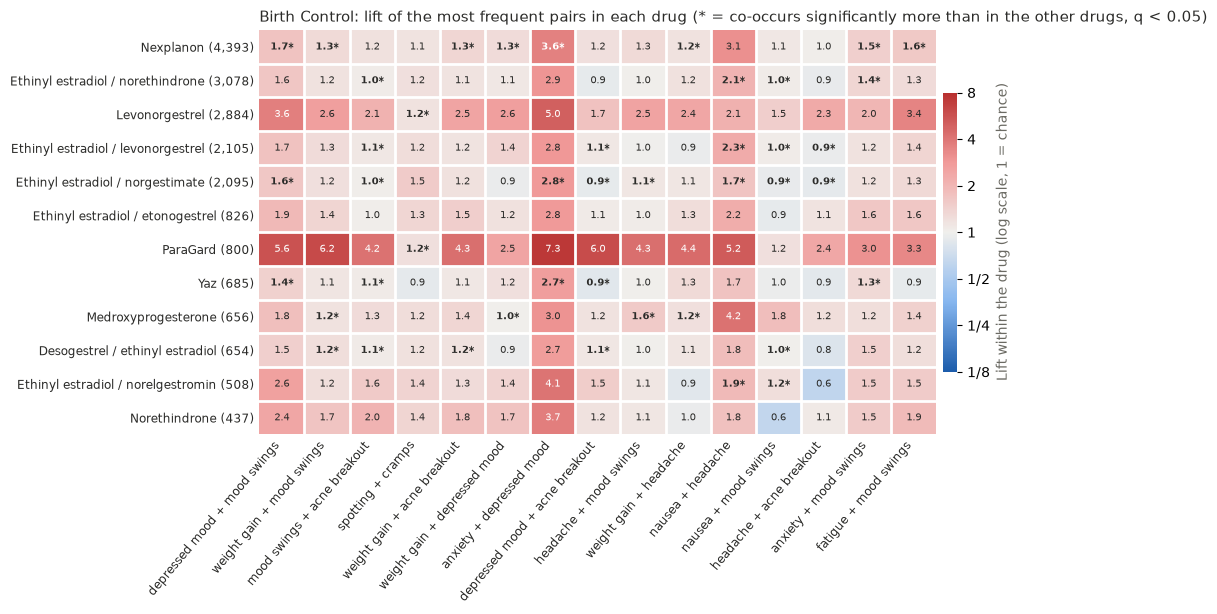

In [32]:
def drug_lift_heatmap(drug_rules, condition, pairs_to_show):
    data = drug_rules[(drug_rules['condition_name'] == condition) & drug_rules['pair'].isin(pairs_to_show)]
    lift = data.pivot(index='drug_family', columns='pair', values='lift')[pairs_to_show]
    order = data.groupby('drug_family')['n_reviews'].first().sort_values(ascending=False).index
    lift = lift.reindex(order)
    star = data.assign(star=(data['q_value'] < FDR) & (data['odds_ratio_vs_other_drugs'] > 1)).pivot(
        index='drug_family', columns='pair', values='star')[pairs_to_show].reindex(order)
    n_reviews = data.groupby('drug_family')['n_reviews'].first().reindex(order)
    log_lift = np.log2(lift.where(lift > 0).values.astype(float))   # lift 0.5 and 2 equally far from 1
    limit = 3.0                                                      # lift 1/8 .. 8
    fig, ax = plt.subplots(figsize=(1.0 + 0.62 * len(pairs_to_show), 1.2 + 0.42 * len(order)))
    image = ax.imshow(np.clip(log_lift, -limit, limit), cmap=LIFT_COLOURS,
                      norm=TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit), aspect='auto')
    for i in range(lift.shape[0]):
        for j in range(lift.shape[1]):
            value = lift.values[i, j]
            if np.isnan(value):
                continue
            dark = abs(np.log2(value)) > 0.6 * limit if value > 0 else True
            ax.text(j, i, f'{value:.1f}' + ('*' if star.values[i, j] else ''), ha='center', va='center', fontsize=7.5,
                    color='white' if dark else INK, fontweight='bold' if star.values[i, j] else 'normal')
    ax.set_xticks(range(len(pairs_to_show)), [p.replace('_', ' ') for p in pairs_to_show], rotation=50, ha='right')
    ax.set_yticks(range(len(order)), [f'{d} ({n_reviews[d]:,})' for d in order])
    ax.set_xticks([x - 0.5 for x in range(1, len(pairs_to_show))], minor=True)
    ax.set_yticks([y - 0.5 for y in range(1, len(order))], minor=True)
    ax.grid(which='minor', color='white', linewidth=2)
    ax.tick_params(which='both', length=0, labelcolor=INK, labelsize=8.5)
    for spine in ax.spines.values():
        spine.set_visible(False)
    bar = fig.colorbar(image, ax=ax, fraction=0.02, pad=0.01, ticks=[-3, -2, -1, 0, 1, 2, 3])
    bar.ax.set_yticklabels(['1/8', '1/4', '1/2', '1', '2', '4', '8'])
    bar.set_label('Lift within the drug (log scale, 1 = chance)', color=MUTED)
    bar.outline.set_visible(False)
    ax.set_title(f'{condition}: lift of the most frequent pairs in each drug '
                 f'(* = co-occurs significantly more than in the other drugs, q < {FDR})', loc='left', color=INK, fontsize=11)
    fig.tight_layout()
    return fig


bc_top_pairs = (condition_pairs[(condition_pairs['condition_name'] == 'Birth Control') & condition_pairs['kept']]
                .sort_values('count', ascending=False)['pair'].head(15).tolist())
fig = drug_lift_heatmap(drug_rules, 'Birth Control', bc_top_pairs)
save_figure(fig, 'drug_lift_heatmap_birth_control.png')
plt.show()

### Drug-specific pairs of every condition
Per condition the 6 rows with the highest odds ratio (at most 2 pairs per drug) among the pairs that pass the three filters: associated at condition level, significantly more frequent with the drug than with the other drugs, and going together inside the drug. Odds ratio ∞ = no other drug of the condition has the pair.

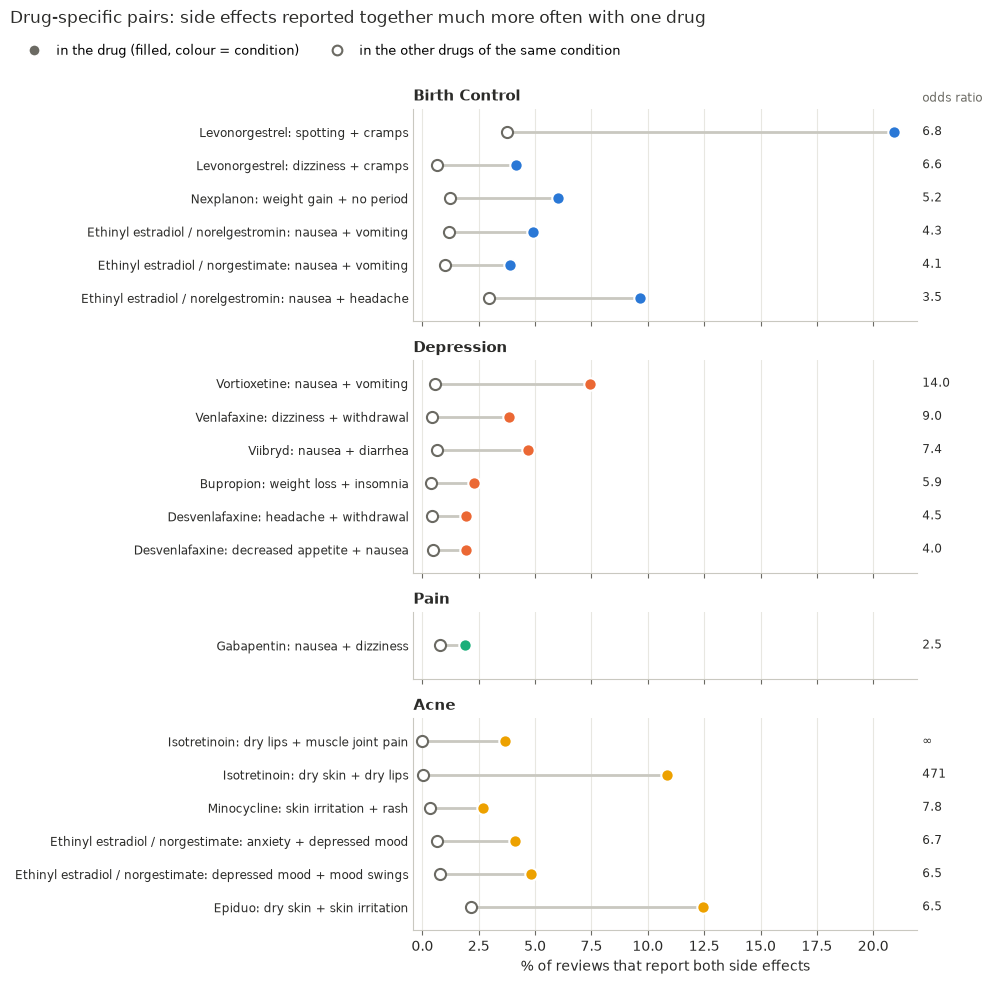

,condition_name,drug_family,pair,n_reviews,count,support,support_other_drugs,lift,lift_other_drugs,odds_ratio_vs_other_drugs,q_value,q_within_drug
0,Acne,Isotretinoin,dry_lips + muscle_joint_pain,682,25,0.037,0.000,1.719,0.000,inf,0.000,0.008
1,Acne,Isotretinoin,dry_skin + dry_lips,682,74,0.109,0.000,1.300,1.665,470.533,0.000,0.010
2,Depression,Vortioxetine,nausea + vomiting,457,34,0.074,0.006,1.915,4.720,13.990,0.000,0.000
3,Depression,Venlafaxine,dizziness + withdrawal,573,22,0.038,0.004,1.701,2.655,8.959,0.000,0.026
4,Acne,Minocycline,skin_irritation + rash,333,9,0.027,0.004,6.529,2.223,7.780,0.000,0.000
5,Depression,Viibryd,nausea + diarrhea,407,19,0.047,0.007,1.969,4.023,7.410,0.000,0.007
6,Birth Control,Levonorgestrel,spotting + cramps,2884,603,0.209,0.037,1.160,1.217,6.795,0.000,0.000
7,Acne,Ethinyl estradiol / norgestimate,anxiety + depressed_mood,269,11,0.041,0.006,4.450,9.131,6.716,0.000,0.000
8,Birth Control,Levonorgestrel,dizziness + cramps,2884,120,0.042,0.007,1.357,1.255,6.583,0.000,0.000
9,Acne,Ethinyl estradiol / norgestimate,depressed_mood + mood_swings,269,13,0.048,0.008,2.629,5.630,6.535,0.000,0.002


In [33]:
def drug_specific_pairs_plot(drug_rules, condition_pairs, top=6, per_drug=2):
    drug_rules = drug_rules.copy()
    drug_rules['q_within_drug'] = benjamini_hochberg(
        [fisher_greater(r.count, r.count_a, r.count_b, r.n_reviews) for r in drug_rules.itertuples()])
    rows = drug_rules.merge(condition_pairs.loc[condition_pairs['kept'], ['condition_name', 'pair']], on=['condition_name', 'pair'])
    rows = rows[(rows['q_value'] < FDR) & (rows['odds_ratio_vs_other_drugs'] > 1) & (rows['q_within_drug'] < FDR)]
    rows = rows.sort_values(['odds_ratio_vs_other_drugs', 'lift'], ascending=False)
    rows = rows.groupby(['condition_name', 'drug_family']).head(per_drug).groupby('condition_name').head(top)
    conditions = [c for c in CONDITION_COLOURS if c in set(rows['condition_name'])]
    sizes = [int((rows['condition_name'] == c).sum()) for c in conditions]

    fig, axes = plt.subplots(len(conditions), 1, sharex=True, figsize=(10, 1.0 + 0.36 * sum(sizes) + 0.5 * len(conditions)),
                             gridspec_kw={'height_ratios': [n + 1.3 for n in sizes]})
    axes = np.atleast_1d(axes)
    x_max = rows[['support', 'support_other_drugs']].max().max() * 100
    for ax, condition in zip(axes, conditions):
        part = rows[rows['condition_name'] == condition].iloc[::-1]       # highest odds ratio on top
        y = np.arange(len(part))
        drug, other = part['support'].to_numpy() * 100, part['support_other_drugs'].to_numpy() * 100
        ax.hlines(y, np.minimum(drug, other), np.maximum(drug, other), color='#c9c8c0', linewidth=2, zorder=1)
        ax.scatter(other, y, s=64, facecolor='white', edgecolor=MUTED, linewidth=1.5, zorder=2)
        ax.scatter(drug, y, s=80, color=CONDITION_COLOURS[condition], edgecolor='white', linewidth=1.5, zorder=3)
        ax.set_yticks(y, [f'{d}: {p.replace("_", " ")}' for d, p in zip(part['drug_family'], part['pair'])])
        ax.set_ylim(-0.7, len(part) - 0.3)
        for yi, ratio in zip(y, part['odds_ratio_vs_other_drugs']):
            text = '∞' if np.isinf(ratio) else f'{ratio:.0f}' if ratio >= 100 else f'{ratio:.1f}'
            ax.text(1.01, yi, text, transform=ax.get_yaxis_transform(), ha='left', va='center', fontsize=8.5, color=INK)
        ax.set_title(condition, loc='left', color=INK, fontsize=10.5, fontweight='bold')
        clean_axes(ax)
        ax.grid(axis='y', visible=False)
        ax.grid(axis='x', color=GRID, linewidth=0.8)
        ax.tick_params(axis='y', length=0, labelsize=8.5)
    axes[0].text(1.01, 1.02, 'odds ratio', transform=axes[0].transAxes, ha='left', va='bottom', fontsize=8.5, color=MUTED)
    axes[-1].set_xlim(-0.4, x_max * 1.05)
    axes[-1].set_xlabel('% of reviews that report both side effects', color=INK)
    handles = [Line2D([], [], marker='o', linestyle='', markersize=8, markerfacecolor=MUTED, markeredgecolor='white',
                      label='in the drug (filled, colour = condition)'),
               Line2D([], [], marker='o', linestyle='', markersize=7, markerfacecolor='white', markeredgecolor=MUTED,
                      markeredgewidth=1.5, label='in the other drugs of the same condition')]
    fig.suptitle('Drug-specific pairs: side effects reported together much more often with one drug',
                 x=0.01, y=0.995, va='top', ha='left', color=INK, fontsize=12)
    fig.legend(handles=handles, loc='upper left', bbox_to_anchor=(0.01, 0.972), ncol=2, frameon=False, fontsize=9)
    fig.tight_layout(rect=(0, 0, 1, 0.962))
    columns = ['condition_name', 'drug_family', 'pair', 'n_reviews', 'count', 'support', 'support_other_drugs',
               'lift', 'lift_other_drugs', 'odds_ratio_vs_other_drugs', 'q_value', 'q_within_drug']
    return fig, rows[columns].reset_index(drop=True)


fig, shown_pairs = drug_specific_pairs_plot(drug_rules, condition_pairs)
save_figure(fig, 'drug_specific_pairs.png')
plt.show()
run_stats['drug_comparison']['drug_specific_examples'] = shown_pairs[['condition_name', 'drug_family', 'pair', 'support', 'support_other_drugs', 'odds_ratio_vs_other_drugs']].round(3).replace(np.inf, 'inf').to_dict(orient='records')
shown_pairs.round(3)

**Conclusion of E10 (research question 2).** Both kinds of pairs exist, and they are different in nature.

- **Universal pairs** are combinations of the condition itself, found with lift > 1 in every drug: menstrual effects together in Birth Control, sexual effects with emotional numbness in Depression, drowsiness with dizziness in Pain, dry lips with dry skin in Acne. They are the shared cost of a drug class, not a property of one medicine.
- **Drug-specific pairs** are the signal for the report: combinations reported together *much* more often with one drug than with its alternatives for the same condition, and that go together inside that drug. The clearest cases are hormonal contraceptives (an implant or injection with its own pattern of bleeding and mood effects, odds ratios far above the rest of the condition) and the acne drug isotretinoin (dry lips with joint pain); in Depression and Pain the differences between drugs are smaller and rest on fewer reviews.
- The lifts are similar in short and long reviews, so the associations are not an artefact of patients who list everything.

What this does not say: rules describe what patients *report* together, after a lexicon with recall 0.67; a pair that is absent for a drug may be under-reported, and the drugs compared are only those with at least 200 reviews in the condition.

### Saving data 

In [34]:
baskets.to_parquet(OUTPUT_DIR / 'baskets.parquet', index=False)
frequent_itemsets.to_csv(OUTPUT_DIR / 'frequent_itemsets.csv', index=False)
rules.to_csv(OUTPUT_DIR / 'rules_by_condition.csv', index=False)
drug_rules.to_csv(OUTPUT_DIR / 'rules_by_drug.csv', index=False)
pair_classes.to_csv(OUTPUT_DIR / 'pair_classification.csv', index=False)
benchmark_table.to_csv(OUTPUT_DIR / 'benchmark.csv', index=False)
print(sorted(path.name for path in OUTPUT_DIR.iterdir()))
print(sorted(path.name for path in FIGURE_DIR.iterdir()))

['baskets.parquet', 'benchmark.csv', 'drug_side_effect_profiles.csv', 'figures', 'frequent_itemsets.csv', 'pair_classification.csv', 'rules_by_condition.csv', 'rules_by_drug.csv']
['benchmark_real.png', 'condition_concept_heatmap.png', 'cooccurrence_networks.png', 'drug_lift_heatmap_birth_control.png', 'drug_specific_pairs.png', 'rating_by_n_side_effects.png', 'support_sensitivity.png']


## Summary for the report
Printed from the run, so it always matches the outputs.

In [35]:
s = run_stats
b, f, r, d, bm = s['baskets'], s['frequent_itemsets'], s['rules'], s['drug_comparison'], s['benchmark']
print(f"""
Data        {s['n_reviews_in_scope']:,} reviews of {s['n_reviews_all']:,} ({len(CONDITIONS)} conditions, {s['n_drug_families_in_scope']} drug families)
Lexicon     {s['n_concepts']} side-effect concepts, {s['n_variants']} variants (v3); blind validation: precision {EXTRACTOR_PRECISION:.2f}, recall {EXTRACTOR_RECALL:.2f}
            (80 reviews not used to build it, gold labels LLM-annotated blind to the extractor)
Baskets     {b['n_mentions']:,} mentions, {b['n_mentions_kept']:,} kept ({b['share_of_mentions_by_filter']['negated']:.1%} negated,
            {b['share_of_mentions_by_filter']['hypothetical']:.1%} hypothetical, {b['share_of_mentions_by_filter']['excluded_indication']:.1%} treated condition);
            {b['share_reviews_with_side_effect']:.1%} of reviews report >= 1 side effect, mean basket size {b['mean_basket_size']:.2f}
Threshold   support >= max({MIN_SUPPORT:.1%} of the condition's reviews, {MIN_COUNT_FLOOR}) -> min_count {f['min_count_by_condition']}
Itemsets    {f['total']['frequent_items']} items, {f['total']['frequent_pairs']} pairs, {f['total']['frequent_triples']} triples (A-priori = PCY = brute force)
Benchmark   PCY {bm['pcy_time_ratio_median']:.1f}x slower than A-priori, removes {bm['pct_candidates_removed_range'][0]:.0f}-{bm['pct_candidates_removed_range'][1]:.0f} % of candidate pairs,
            but A-priori's pass 2 needs at most {bm['apriori_pass2_KB_max']:.1f} KB: no memory to save with 57 items
Rules       {r['n_rules_kept']} of {r['n_rules']} rules kept (count >= {MIN_RULE_COUNT}, confidence >= {MIN_CONFIDENCE}, lift > {MIN_LIFT:g}, q < {FDR}); per condition {r['kept_by_condition']}
RQ2         {d['n_tests']:,} drug x pair tests ({d['n_significant']} significant); of {d['n_pairs_associated']} associated pairs,
            {d['n_universal_pairs']} universal and {d['n_drug_specific_pairs']} drug-specific (a pair can be both)
Runtime     {(time.perf_counter() - NOTEBOOK_STARTED) / 60:.1f} minutes
""")


Data        36,365 reviews of 128,663 (4 conditions, 168 drug families)
Lexicon     57 side-effect concepts, 450 variants (v3); blind validation: precision 0.74, recall 0.67
            (80 reviews not used to build it, gold labels LLM-annotated blind to the extractor)
Baskets     104,986 mentions, 73,948 kept (12.7% negated,
            0.5% hypothetical, 18.1% treated condition);
            72.3% of reviews report >= 1 side effect, mean basket size 1.72
Threshold   support >= max(0.5% of the condition's reviews, 20) -> min_count {'Birth Control': 98, 'Depression': 36, 'Pain': 26, 'Acne': 23}
Itemsets    126 items, 209 pairs, 86 triples (A-priori = PCY = brute force)
Benchmark   PCY 1.8x slower than A-priori, removes 80-98 % of candidate pairs,
            but A-priori's pass 2 needs at most 3.0 KB: no memory to save with 57 items
Rules       391 of 934 rules kept (count >= 20, confidence >= 0.1, lift > 1, q < 0.05); per condition {'Birth Control': 313, 'Depression': 49, 'Pain': 10,

## Save all statistics for the report

In [36]:
run_stats['runtime_minutes'] = round((time.perf_counter() - NOTEBOOK_STARTED) / 60, 1)


def json_safe(value):
    # numpy numbers and booleans -> plain Python
    if hasattr(value, 'item'):
        return value.item()
    return str(value)


(OUTPUT_DIR / 'role_e_run_stats.json').write_text(json.dumps(run_stats, indent=2, default=json_safe), encoding='utf-8')
print(json.dumps({k: v for k, v in run_stats.items() if k not in ('support_sensitivity', 'benchmark_bucket_sweep')},
                 indent=1, default=json_safe)[:6000])

{
 "n_reviews_all": 128663,
 "n_reviews_in_scope": 36365,
 "n_drug_families_in_scope": 168,
 "scope_by_condition": {
  "Birth Control": {
   "n_reviews": 19520,
   "n_drugs": 19,
   "mean_rating": 6.083,
   "share_negative": 0.351
  },
  "Depression": {
   "n_reviews": 7109,
   "n_drugs": 52,
   "mean_rating": 7.132,
   "share_negative": 0.218
  },
  "Pain": {
   "n_reviews": 5187,
   "n_drugs": 72,
   "mean_rating": 7.585,
   "share_negative": 0.176
  },
  "Acne": {
   "n_reviews": 4549,
   "n_drugs": 34,
   "mean_rating": 7.362,
   "share_negative": 0.2
  }
 },
 "lexicon_versions": {
  "v1": {
   "n_concepts": 49,
   "n_variants": 298
  },
  "v2": {
   "n_concepts": 57,
   "n_variants": 383
  },
  "v3": {
   "n_concepts": 57,
   "n_variants": 450
  }
 },
 "n_concepts": 57,
 "n_variants": 450,
 "extractor_validation": {
  "precision": 0.74,
  "recall": 0.67,
  "n_reviews": 80,
  "round": 2,
  "gold_labels": "LLM-annotated (Claude), blind to the extractor"
 },
 "lexicon_expansion": {
 